One huge notebook
# Notebook to reproduce ICOCO

Single top-to-bottom notebook reproducing *"Reducing Generative AI Bias in Food Recognition
Using a Multi-Dimensional Culinary Representation Framework"* (`ICOCO IEEE eXPress.pdf`):
raw data → LLM canonicalization + grounding metrics → GBIF → the 304-D non-semantic vectors
(+ FoodBERT baseline) → the K-means "battle" → figures.

**Data:** FooDB / FoodUSDA / Zenodo and every pre-computed artifact (merged LLM files,
mapping jsons, GBIF caches, `.npy` vectors) are fetched from a **GitHub
Release** (`GH_RELEASE` below) because the upstream servers block programmatic downloads.

**Scope:** FoodBERT embeddings (section 3.4) and the K-means "battle" (section 5) are
**executed here** — K-means runs on the **GPU**. The other `.npy` vectors are reused
from the Release. All SQL is idempotent (`CREATE OR REPLACE` / `IF NOT EXISTS`).


# 0. Environment & data setup

In [ ]:
# ======= GLOBAL CONFIG (Google Colab) =======
import os
DATA      = '/content'                 # working dir; uploaded / downloaded files live here
DB        = '/content/ICOCO.duckdb'    # the single DuckDB database file
ARTIFACTS = '/content'                 # pre-computed .npy vectors live here
OUTDIR    = '/content'                 # where (re)generated .npy are written
FOODBERT_NPY = '/content/foodbert_Zenodo.npy'

# GitHub Release hosting the `final/data/` payload (raw archives, merged LLM files,
# mapping jsons, GBIF caches, and the pre-computed .npy vectors).
# Sửa 'artifacts' -> 'artifacts02'
GH_RELEASE = 'https://github.com/hoangvanminhforwork-sleeping/food-and-non-semantic-vector/releases/download/artifacts02'

# Scope flags.
REGENERATE_VECTORS = True   # False -> load the pre-computed .npy (reuse artifacts)
RUN_FOODBERT       = True    # clone + run FoodBERT to build foodbert_Zenodo.npy (section 3.4)
RUN_KMEANS         = True    # run the K-means battle on the GPU (section 5)
KMEANS_DEVICE      = 'cuda'   # 'cuda' -> GPU (Colab); falls back to CPU if CUDA is unavailable
EXT_ASSIGN = 'bipartite'  # external cluster->label rule (cell 5.3):
                       #   'bipartite' strict Hungarian bijection for EVERY model -- the rule the
                       #               paper describes (Sec. IV-C / Eq. 7).  DEFAULT: the only
                       #               rule that keeps the variants distinguishable.
                       #   'argmax'    per-cluster majority for every model.  DEGENERATE: at K=6
                       #               every cluster's modal continent is 'North America', so
                       #               every variant scores the majority-class base rate
                       #               (PA 71.76 / SF1 0.1393) and all Fig. 4 bars look like
                       #               'Our Full Fusion'.
                       #   'legacy'    FoodBERT bijection + per-cluster majority for the 6
                       #               proposed models (the mixture behind the old labeled.csv)
                       #               -> the same collapse for those variants.

# one merged file per LLM task: {custom_id, input, output1, output2, output3}
LLM_TASKS = ['ingredient_standardize', 'scientific_name', 'cuisine_normalize', 'odor']
print('DATA =', DATA); print('DB =', DB); print('GH_RELEASE =', GH_RELEASE)
FIG3_SOURCE = 'computed'  # External figures (6.1 + 6.2) source: 'paper' (published reference
                       # values, old_code/.../result/labeled.csv) | 'computed' (this notebook)


DATA = /content
DB = /content/ICOCO.duckdb
GH_RELEASE = https://github.com/hoangvanminhforwork-sleeping/food-and-non-semantic-vector/releases/download/artifacts02


In [ ]:
# Install only what Colab does NOT already ship.
# (numpy, pandas, scipy, matplotlib, seaborn, plotly, scikit-learn, torch, transformers are preinstalled.)
!pip -q install duckdb duckdb-engine jupysql requests


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.8/192.8 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 23.4 MB/s eta 0:00:00


In [ ]:
!python3 -c "import duckdb; conn = duckdb.connect('ICOCO.duckdb'); conn.close()"

## 0.2 Download datasets (Zenodo + GitHub Release)

In [ ]:
import os, requests
from tqdm import tqdm

# ---- Zenodo recipe corpus (record 15169428) ----
RECORD_ID, FILE_NAME = '15169428', 'dataset.csv'
_save = f'{DATA}/{FILE_NAME}'
if os.path.exists(_save):
    print('already downloaded:', _save)
else:
    _url = f'https://zenodo.org/records/{RECORD_ID}/files/{FILE_NAME}?download=1'
    _r = requests.get(_url, stream=True); _total = int(_r.headers.get('content-length', 0))
    with open(_save, 'wb') as f, tqdm(total=_total, unit='iB', unit_scale=True, desc=FILE_NAME) as bar:
        for chunk in _r.iter_content(1024):
            bar.update(len(chunk)); f.write(chunk)
    print('saved', _save)

dataset.csv: 110MiB [00:26, 4.20MiB/s]

saved /content/dataset.csv


In [ ]:
import os, shutil, tarfile, zipfile, requests
from tqdm.auto import tqdm

def _download(url, out):
    # Idempotent check: Chỉ bỏ qua nếu file đã tồn tại và dung lượng > 0
    if os.path.exists(out) and os.path.getsize(out) > 0:
        print('Already downloaded:', out)
        return out

    r = requests.get(url, stream=True)
    r.raise_for_status()  # Báo lỗi ngay nếu sai URL (404/500)

    total = int(r.headers.get('content-length', 0))

    try:
        with open(out, 'wb') as f, tqdm(
            total=total,
            unit='iB',
            unit_scale=True,
            unit_divisor=1024,
            desc=os.path.basename(out)
        ) as bar:
            for chunk in r.iter_content(chunk_size=8192):
                if chunk:
                    f.write(chunk)
                    bar.update(len(chunk))
    except Exception as e:
        # Xóa file chưa tải xong nếu có lỗi ngắt quãng
        if os.path.exists(out):
            os.remove(out)
        raise e
    return out

def _extract(archive, folder, inner_hint=None):
    # Idempotent check: Nếu thư mục đích đã tồn tại thì không giải nén lại
    if os.path.isdir(folder):
        print('Already extracted:', folder)
        return folder

    tmp = folder + '_tmp'
    if os.path.exists(tmp):
        shutil.rmtree(tmp)
    os.makedirs(tmp, exist_ok=True)

    try:
        if archive.endswith('.zip'):
            with zipfile.ZipFile(archive) as zf:
                zf.extractall(tmp)
        else:
            with tarfile.open(archive) as tf:
                tf.extractall(tmp)
    except Exception as e:
        # Nếu giải nén lỗi (do nén hỏng/file rác), xóa file archive để tự tải lại ở lần sau
        if os.path.exists(archive):
            os.remove(archive)
        if os.path.exists(tmp):
            shutil.rmtree(tmp)
        raise RuntimeError(f"Archive {archive} bị hỏng đã được xóa. Hãy chạy lại script để tải lại!") from e

    # Tìm thư mục con bên trong tmp và chuyển ra folder chính
    content_list = os.listdir(tmp)
    if not content_list:
        shutil.rmtree(tmp)
        raise FileNotFoundError(f"Thư mục giải nén tạm {tmp} trống!")

    inner = os.path.join(tmp, inner_hint or content_list[0])

    # Nếu inner là thư mục thì di chuyển, nếu là các file đơn lẻ thì copy toàn bộ
    if os.path.isdir(inner):
        shutil.move(inner, folder)
    else:
        shutil.move(tmp, folder)

    if os.path.exists(tmp):
        shutil.rmtree(tmp)

    print('Extracted ->', folder)
    return folder


# ---- FooDB ----
_foodb = _download(f'{GH_RELEASE}/foodb_2020_4_7_csv.tar.gz', f'{DATA}/foodb_2020_4_7_csv.tar.gz')
_extract(_foodb, f'{DATA}/foodb_2020_04_07')
print('FooDB:', sorted(os.listdir(f'{DATA}/foodb_2020_04_07'))[:4])

# ---- FoodUSDA (foundation = latest, and SR legacy) ----
_usda_latest = _download(
    f'{GH_RELEASE}/FoodData_Central_foundation_food_csv_2026-04-30.zip',
    f'{DATA}/FoodData_Central_foundation_food_csv_2026-04-30.zip'
)
_extract(_usda_latest, f'{DATA}/foodusda_latest')

# LƯU Ý: Sửa tên file .2018-04.1.zip theo đúng trên GitHub Assets
_usda_legacy = _download(
    f'{GH_RELEASE}/FoodData_Central_sr_legacy_food_csv_2018-04.1.zip',
    f'{DATA}/FoodData_Central_sr_legacy_food_csv_2018-04.1.zip'
)
_extract(_usda_legacy, f'{DATA}/foodusda_legacy')

# Kiểm tra kết quả
print('FoodUSDA latest:', sorted(os.listdir(f'{DATA}/foodusda_latest'))[:4])
print('FoodUSDA legacy:', sorted(os.listdir(f'{DATA}/foodusda_legacy'))[:4])

foodb_2020_4_7_csv.tar.gz:   0%|          | 0.00/953M [00:00<?, ?iB/s]

/tmp/ipykernel_1832/146067301.py:51: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(tmp)


Extracted -> /content/foodb_2020_04_07
FooDB: ['.DS_Store', '._.DS_Store', 'AccessionNumber.csv', 'Compound.csv']


FoodData_Central_foundation_food_csv_2026-04-30.zip:   0%|          | 0.00/3.65M [00:00<?, ?iB/s]

Extracted -> /content/foodusda_latest


FoodData_Central_sr_legacy_food_csv_2018-04.1.zip:   0%|          | 0.00/5.79M [00:00<?, ?iB/s]

Extracted -> /content/foodusda_legacy
FoodUSDA latest: ['Download API Field Descriptions.xlsx', 'acquisition_samples.csv', 'agricultural_samples.csv', 'food.csv']
FoodUSDA legacy: ['Download & API Field Descriptions-2019-10-11-16-22.xlsx', 'all_downloaded_table_record_counts.csv', 'food.csv', 'food_attribute.csv']


## 0.2b Fetch the pre-computed artifacts (GitHub Release)

In [ ]:
# Download helper for the GitHub Release artifacts (idempotent: skips what is present).
import os, requests
from tqdm import tqdm

def fetch(name, dest=None):
    dest = dest or f'{DATA}/{name}'
    if os.path.exists(dest):
        print('present:', dest); return dest
    url = f'{GH_RELEASE}/{name}'
    r = requests.get(url, stream=True); r.raise_for_status()
    total = int(r.headers.get('content-length', 0))
    with open(dest, 'wb') as f, tqdm(total=total, unit='iB', unit_scale=True, desc=name) as bar:
        for chunk in r.iter_content(1 << 20):
            bar.update(len(chunk)); f.write(chunk)
    print('downloaded:', dest); return dest


In [ ]:
# Fetch the pre-computed artifacts from the GitHub Release (reuse, do NOT regenerate).
# NOTE: `foodbert_Zenodo.npy` is intentionally NOT fetched -- it is *built* here (section 3.4).
ARTIFACTS_TO_FETCH = [
    'ingredient_standardize_merged.jsonl', 'scientific_name_merged.jsonl',
    'cuisine_normalize_merged.jsonl', 'odor_merged.jsonl',
    'dirty_ingredient_category_mapping.json', 'dirty_ingredient_nutrient_mapping.json',
    'reaction_cooking.py', 'coutries.csv',
    'gbif_species_match.jsonl', 'dirty_ingredient_country_mapping.json',
    'recipe_geography_vectors.npy', 'entity_vectors.npy',
    'recipe_odor_vectors.npy', 'recipe_odor_entropy.npy',
]
for _n in ARTIFACTS_TO_FETCH:
    try:
        fetch(_n)
    except Exception as _e:
        print('  (optional, skipped)', _n, '->', _e)
print('artifact fetch step done')


ingredient_standardize_merged.jsonl: 100%|██████████| 72.8k/72.8k [00:00<00:00, 5.51MiB/s]


downloaded: /content/ingredient_standardize_merged.jsonl


scientific_name_merged.jsonl: 100%|██████████| 1.11M/1.11M [00:00<00:00, 23.0MiB/s]


downloaded: /content/scientific_name_merged.jsonl


cuisine_normalize_merged.jsonl: 100%|██████████| 72.8k/72.8k [00:00<00:00, 6.42MiB/s]


...

downloaded: /content/coutries.csv


gbif_species_match.jsonl: 100%|██████████| 99.7k/99.7k [00:00<00:00, 7.36MiB/s]


downloaded: /content/gbif_species_match.jsonl


dirty_ingredient_country_mapping.json: 100%|██████████| 365k/365k [00:00<00:00, 10.9MiB/s]


downloaded: /content/dirty_ingredient_country_mapping.json
  (optional, skipped) recipe_geography_vectors.npy -> 404 Client Error: Not Found for url: https://github.com/hoangvanminhforwork-sleeping/food-and-non-semantic-vector/releases/download/artifacts02/recipe_geography_vectors.npy
  (optional, skipped) entity_vectors.npy -> 404 Client Error: Not Found for url: https://github.com/hoangvanminhforwork-sleeping/food-and-non-semantic-vector/releases/download/artifacts02/entity_vectors.npy
  (optional, skipped) recipe_odor_vectors.npy -> 404 Client Error: Not Found for url: https://github.com/hoangvanminhforwork-sleeping/food-and-non-semantic-vector/releases/download/artifacts02/recipe_odor_vectors.npy
  (optional, skipped) recipe_odor_entropy.npy -> 404 Client Error: Not Found for url: https://github.com/hoangvanminhforwork-sleeping/food-and-non-semantic-vector/releases/download/artifacts02/recipe_odor_entropy.npy
artifact fetch step done


## 0.4 Verify the data

In [ ]:
# --- 0.4 Verify the data ---------------------------------------------------------
# Hard requirements: the LLM/reference inputs.  Soft requirements: the pre-computed
# `.npy` vectors -- if one is missing it is IGNORED here and simply (re)built later,
# so an absent/foreign vector file never disrupts the top-to-bottom Colab flow.
import os
npy_artifacts = [
    f'{DATA}/recipe_geography_vectors.npy', f'{DATA}/entity_vectors.npy',
    f'{DATA}/recipe_odor_vectors.npy', f'{DATA}/recipe_odor_entropy.npy',
]
required = [f'{DATA}/{t}_merged.jsonl' for t in LLM_TASKS] + [
    f'{DATA}/dirty_ingredient_category_mapping.json',   # ingredient -> USDA category (entity vector)
    f'{DATA}/dirty_ingredient_nutrient_mapping.json',   # ingredient -> nutrients (odor vector)
    f'{DATA}/reaction_cooking.py',                      # cooking-method -> reactions config
    f'{DATA}/coutries.csv',                             # country-code reference
] + npy_artifacts

missing = [p for p in required if not os.path.exists(p)]
print('required files present:', len(required) - len(missing), '/', len(required))
for p in required:
    print(('  OK   ' if os.path.exists(p) else '  MISS ') + p)

# Only the non-`.npy` inputs are truly required; a missing `.npy` (or FoodBERT) is
# tolerated -- it is (re)generated by the vector sections, so the flow keeps going.
hard_missing = [p for p in missing if not p.endswith('.npy')]
try:
    assert not hard_missing, (
        'Missing non-vector inputs (fetch them from the GitHub Release into ' + DATA
        + '): ' + ', '.join(hard_missing))
    if missing:
        print('NOTE: these pre-computed .npy are missing and will be ignored/rebuilt:',
              [os.path.basename(p) for p in missing])
except AssertionError as e:
    print('WARNING:', e)


required files present: 8 / 12
  OK   /content/ingredient_standardize_merged.jsonl
  OK   /content/scientific_name_merged.jsonl
  OK   /content/cuisine_normalize_merged.jsonl
  OK   /content/odor_merged.jsonl
  OK   /content/dirty_ingredient_category_mapping.json
  OK   /content/dirty_ingredient_nutrient_mapping.json
  OK   /content/reaction_cooking.py
  OK   /content/coutries.csv
  MISS /content/recipe_geography_vectors.npy
  MISS /content/entity_vectors.npy
  MISS /content/recipe_odor_vectors.npy
  MISS /content/recipe_odor_entropy.npy
NOTE: these pre-computed .npy are missing and will be ignored/rebuilt: ['recipe_geography_vectors.npy', 'entity_vectors.npy', 'recipe_odor_vectors.npy', 'recipe_odor_entropy.npy']


## 0.3 Open DuckDB (connect → flush WAL → reconnect)

In [ ]:
%load_ext sql
%config SqlMagic.displaylimit = 50
%sql duckdb:////content/ICOCO.duckdb

Connecting to 'duckdb:////content/ICOCO.duckdb'

In [ ]:
# Close first to flush the write-ahead log, then reconnect fresh.
%sql --close duckdb:////content/ICOCO.duckdb

In [ ]:
%sql duckdb:////content/ICOCO.duckdb

Connecting and switching to connection 'duckdb:////content/ICOCO.duckdb'

In [ ]:
from sql.connection import ConnectionManager
# DuckDB allows ONE connection only -> reuse the one %sql opened (never duckdb.connect() again).
raw = ConnectionManager().current.connection_sqlalchemy.connection
raw.execute("SET memory_limit = '8GB'")
raw.execute("SET threads = 12")
print('reusing the single %sql connection:', raw)

reusing the single %sql connection: <sqlalchemy.pool.base._ConnectionFairy object at 0x787e666d6c90>


# 1. Final tables + LLM outputs + performance

## 1.1 Create schemas

In [ ]:
%%sql
CREATE SCHEMA IF NOT EXISTS zenodo;
CREATE SCHEMA IF NOT EXISTS foodb;
CREATE SCHEMA IF NOT EXISTS foodusda_latest;
CREATE SCHEMA IF NOT EXISTS foodusda_legacy;
CREATE SCHEMA IF NOT EXISTS ingredient_standardize;
CREATE SCHEMA IF NOT EXISTS scientific_name;
CREATE SCHEMA IF NOT EXISTS cuisine_normalize;
CREATE SCHEMA IF NOT EXISTS odor;
CREATE SCHEMA IF NOT EXISTS gbif;
CREATE SCHEMA IF NOT EXISTS metrics;
CREATE SCHEMA IF NOT EXISTS battle;
CREATE SCHEMA IF NOT EXISTS result;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


## 1.2 Reference datasets (countries, FooDB, FoodUSDA) — straight to the final tables

In [ ]:
%%sql
-- Country code reference (fixed column order for the geography vector)
CREATE OR REPLACE TABLE zenodo.countries AS
SELECT * FROM read_csv('/content/coutries.csv', header=true);

-- FooDB flavour table (keep only the emitted columns)
CREATE OR REPLACE TABLE foodb.flavor AS
SELECT id, name, flavor_group, category
FROM read_csv('/content/foodb_2020_04_07/Flavor.csv', header=true, sample_size=-1);

-- FoodUSDA latest (foundation food)
CREATE OR REPLACE TABLE foodusda_latest.food_category AS
SELECT * FROM read_csv('/content/foodusda_latest/food_category.csv', header=true, sample_size=-1);
CREATE OR REPLACE TABLE foodusda_latest.food AS
SELECT fdc_id, data_type, description, food_category_id FROM read_csv('/content/foodusda_latest/food.csv', header=true, sample_size=-1);
CREATE OR REPLACE TABLE foodusda_latest.nutrient AS
SELECT id, name FROM read_csv('/content/foodusda_latest/nutrient.csv', header=true, sample_size=-1);
CREATE OR REPLACE TABLE foodusda_latest.food_nutrient AS
SELECT id, fdc_id, nutrient_id FROM read_csv('/content/foodusda_latest/food_nutrient.csv', header=true, sample_size=-1);

-- FoodUSDA legacy (SR legacy)
CREATE OR REPLACE TABLE foodusda_legacy.food_category AS
SELECT * FROM read_csv('/content/foodusda_legacy/food_category.csv', header=true, sample_size=-1);
CREATE OR REPLACE TABLE foodusda_legacy.food AS
SELECT fdc_id, data_type, description, food_category_id FROM read_csv('/content/foodusda_legacy/food.csv', header=true, sample_size=-1);
CREATE OR REPLACE TABLE foodusda_legacy.nutrient AS
SELECT id, name FROM read_csv('/content/foodusda_legacy/nutrient.csv', header=true, sample_size=-1);
CREATE OR REPLACE TABLE foodusda_legacy.food_nutrient AS
SELECT id, fdc_id, nutrient_id FROM read_csv('/content/foodusda_legacy/food_nutrient.csv', header=true, sample_size=-1);

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


## 1.3 Zenodo recipes → `zenodo.recipes`

In [ ]:
import csv
import re

# DuckDB 1.1.3's read_csv has NO 'encoding' parameter (unlike older versions),
# so the cp1252 file must be converted to UTF-8 first. The raw file also contains
# control characters and unescaped double-quotes that break DuckDB's strict CSV
# parser, so we re-emit a properly-quoted UTF-8 CSV with Python's csv module.

SRC = '/content/dataset.csv'
TMP = '/content/zenodo_utf8.csv'
OUT = '/content/zenodo_final.csv'

# Step 1: cp1252 -> UTF-8 and strip control characters (e.g. NUL)
CTRL = re.compile(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]')
with open(SRC, 'rb') as fh, open(TMP, 'w', newline='', encoding='utf-8') as fo:
    for line in fh:
        fo.write(CTRL.sub('', line.decode('cp1252')))

# Step 2: re-quote fields properly (fixes unescaped double-quotes)
with open(TMP, newline='', encoding='utf-8') as fh, open(OUT, 'w', newline='', encoding='utf-8') as fo:
    reader = csv.reader(fh, delimiter=';', quotechar='"')
    writer = csv.writer(fo, delimiter=';', quotechar='"', quoting=csv.QUOTE_MINIMAL, lineterminator='\n')
    for row in reader:
        if len(row) != 18:  # skip malformed rows
            continue
        writer.writerow(row)

print('Preprocessed CSV ready:', OUT)

Preprocessed CSV ready: /content/zenodo_final.csv


In [ ]:
%%sql
CREATE OR REPLACE TABLE zenodo.recipes AS
SELECT * FROM read_csv(
    '/content/zenodo_final.csv',
    delim=';',
    header=true,
    quote='"',
    ignore_errors=true,
    null_padding=true,
    parallel=false
);

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
import ast
from sql.connection import ConnectionManager

# IMPORTANT: DuckDB allows only ONE connection to the database at a time.
# Reuse the SAME connection that %sql already opened (do NOT duckdb.connect() again).
raw = ConnectionManager().current.connection_sqlalchemy.connection

# Read the full copy from silver (never touch bronze)
df = raw.execute('SELECT "Name", "Category", "Cuisine", "Ingredients", "Cooking Methods" FROM zenodo.recipes').df()

def parse_list(x):
    """Parse a Python-list literal stored as VARCHAR into a real list."""
    try:
        v = ast.literal_eval(x)
        return v if isinstance(v, list) else []
    except Exception:
        return []

# Category / Cuisine / Cooking Methods are plain lists of strings
for col in ['Category', 'Cuisine', 'Cooking Methods']:
    df[col] = df[col].apply(parse_list)

# Ingredients is a list of dicts -> keep only the ingredient name
def parse_ingredients(x):
    try:
        v = ast.literal_eval(x)
        if isinstance(v, list):
            return [d['ingredient'] for d in v if isinstance(d, dict) and 'ingredient' in d]
    except Exception:
        pass
    return []

df['Ingredients'] = df['Ingredients'].apply(parse_ingredients)

# Write the curated table back to silver (CREATE OR REPLACE keeps it re-runnable)
# register() creates a temporary view; materialize it into the real table, then drop the view.
raw.register('df_zenodo', df)
raw.execute('CREATE OR REPLACE TABLE zenodo.recipes AS SELECT * FROM df_zenodo')
raw.execute('DROP VIEW IF EXISTS df_zenodo')

print('zenodo.recipes rows:', len(df))
print(df.head(2).to_string())

zenodo.recipes rows: 50511
                      Name             Category         Cuisine                                                                                                                                                             Ingredients Cooking Methods
0  Pineapple Glaze for Ham             [Dinner]      [American]                                                                                                                           [pineapple, maraschino cherries, brown sugar]     [microwave]
1        Awesome Egg Rolls  [Dinner, Appetizer]  [World, Asian]  [vegetable oil, egg, cabbage, bean sprouts, carrot, stalk, onion, shrimp, soy sauce, garlic powder, pepper to taste, cornstarch, oil for frying, water, roll wrappers]           [fry]


## 1.4 Upload the LLM outputs — one schema per task, `output1/2/3` replicas

In [ ]:
%%sql
-- ingredient standardization + taxonomic extraction: keep the merged (input + 3 replicas) shape
CREATE OR REPLACE TABLE ingredient_standardize.runs AS
SELECT custom_id::VARCHAR AS custom_id, input::VARCHAR AS input,
       output1::VARCHAR AS output1, output2::VARCHAR AS output2, output3::VARCHAR AS output3
FROM read_json_auto('/content/ingredient_standardize_merged.jsonl', format='newline_delimited');

CREATE OR REPLACE TABLE scientific_name.runs AS
SELECT custom_id::VARCHAR AS custom_id, input::VARCHAR AS input,
       output1::VARCHAR AS output1, output2::VARCHAR AS output2, output3::VARCHAR AS output3
FROM read_json_auto('/content/scientific_name_merged.jsonl', format='newline_delimited');

SELECT 'ingredient_standardize.runs' AS tbl, count(*) AS rows FROM ingredient_standardize.runs
UNION ALL SELECT 'scientific_name.runs', count(*) FROM scientific_name.runs;

Running query in 'duckdb:////content/ICOCO.duckdb'

tbl,rows
ingredient_standardize.runs,116
scientific_name.runs,4280


In [ ]:
# cuisine_normalize (object content) and odor (list content): parse the 3 replicas into typed list columns.
import json, pandas as pd
from sql.connection import ConnectionManager
_con = ConnectionManager().current.connection_sqlalchemy.connection.driver_connection

def _load(path):
    return [json.loads(l) for l in open(path, encoding='utf-8') if l.strip()]

def _clean(s):
    s = (s or '').strip()
    return s.strip('`').strip() if s.startswith('```') else s

def _write(schema, ver, recs):
    df = pd.DataFrame(recs)
    _con.register('_stage', df)
    _con.execute('CREATE OR REPLACE TABLE ' + schema + '.' + ver + ' AS SELECT * FROM _stage')
    _con.unregister('_stage')

# ---- cuisine_normalize: {"country_list": [...], "sub_region_list": [...], "continent_list": [...]} ----
_cui = _load('/content/cuisine_normalize_merged.jsonl')
for v in ['output1', 'output2', 'output3']:
    recs = []
    for o in _cui:
        try:
            d = json.loads(_clean(o[v]))
            if not isinstance(d, dict): d = {}
        except Exception:
            d = {}
        recs.append({'custom_id': o['custom_id'], 'input_text': o['input'],
                     'country_list': d.get('country_list') or [],
                     'sub_region_list': d.get('sub_region_list') or [],
                     'continent_list': d.get('continent_list') or []})
    _write('cuisine_normalize', v, recs)

# ---- odor: ["balsamic", "nutty", ...] ----
_odo = _load('/content/odor_merged.jsonl')
for v in ['output1', 'output2', 'output3']:
    recs = []
    for o in _odo:
        try:
            d = json.loads(_clean(o[v]))
            lst = d if isinstance(d, list) else []
        except Exception:
            lst = []
        recs.append({'custom_id': o['custom_id'], 'input_text': o['input'], 'value_list': lst})
    _write('odor', v, recs)

print('cuisine_normalize + odor replica tables ready')

cuisine_normalize + odor replica tables ready


## 1.5 Verify the LLM input

In [ ]:
%%sql
SELECT (SELECT count(DISTINCT lower(trim(ing))) FROM zenodo.recipes, UNNEST(Ingredients) AS t(ing)) AS recipe_ingredient_vocab,
       (SELECT count(*) FROM ingredient_standardize.runs) AS ingredient_llm_inputs,
       (SELECT count(*) FROM scientific_name.runs)        AS scientific_llm_inputs,
       (SELECT count(*) FROM cuisine_normalize.output1)   AS cuisine_tags,
       (SELECT count(*) FROM odor.output1)                AS odor_inputs;

Running query in 'duckdb:////content/ICOCO.duckdb'

recipe_ingredient_vocab,ingredient_llm_inputs,scientific_llm_inputs,cuisine_tags,odor_inputs
17014,116,4280,116,3792


## 1.6 LLM performance — parsing layer

In [ ]:
%%sql
CREATE OR REPLACE VIEW metrics.v_ingredient_runs AS
WITH runs AS (
    SELECT custom_id::VARCHAR AS custom_id, 'o1' AS run_idx, output1::VARCHAR AS raw FROM ingredient_standardize.runs
    UNION ALL
    SELECT custom_id::VARCHAR, 'o2', output2::VARCHAR FROM ingredient_standardize.runs
    UNION ALL
    SELECT custom_id::VARCHAR, 'o3', output3::VARCHAR FROM ingredient_standardize.runs
),
parsed AS (
    SELECT
        custom_id, run_idx, raw,
            regexp_replace(raw, '^\s+|\s+$', '') AS ws,
        CASE WHEN json_valid(    regexp_replace(raw, '^\s+|\s+$', '')) AND starts_with(    regexp_replace(raw, '^\s+|\s+$', ''), '[') AND ends_with(    regexp_replace(raw, '^\s+|\s+$', ''), ']')
             THEN 'list' ELSE 'string' END AS parsed_kind,
        CASE WHEN json_valid(    regexp_replace(raw, '^\s+|\s+$', '')) AND starts_with(    regexp_replace(raw, '^\s+|\s+$', ''), '[') AND ends_with(    regexp_replace(raw, '^\s+|\s+$', ''), ']')
             THEN list_transform(from_json(    regexp_replace(raw, '^\s+|\s+$', ''), '["VARCHAR"]'), x -> lower(trim(x)))
             ELSE NULL END AS value_list,
        CASE WHEN json_valid(    regexp_replace(raw, '^\s+|\s+$', '')) AND starts_with(    regexp_replace(raw, '^\s+|\s+$', ''), '[') AND ends_with(    regexp_replace(raw, '^\s+|\s+$', ''), ']')
             THEN NULL ELSE lower(    regexp_replace(raw, '^\s+|\s+$', '')) END AS norm_str
    FROM runs
)
SELECT * FROM parsed;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
CREATE OR REPLACE VIEW metrics.v_scientific_runs AS
WITH runs AS (
    SELECT custom_id::VARCHAR AS custom_id, 'o1' AS run_idx, output1::VARCHAR AS raw FROM scientific_name.runs
    UNION ALL
    SELECT custom_id::VARCHAR, 'o2', output2::VARCHAR FROM scientific_name.runs
    UNION ALL
    SELECT custom_id::VARCHAR, 'o3', output3::VARCHAR FROM scientific_name.runs
),
parsed AS (
    SELECT
        custom_id, run_idx, raw,
            regexp_replace(raw, '^\s+|\s+$', '') AS ws,
        CASE WHEN json_valid(    regexp_replace(raw, '^\s+|\s+$', '')) AND starts_with(    regexp_replace(raw, '^\s+|\s+$', ''), '[') AND ends_with(    regexp_replace(raw, '^\s+|\s+$', ''), ']')
             THEN 'list' ELSE 'string' END AS parsed_kind,
        CASE WHEN json_valid(    regexp_replace(raw, '^\s+|\s+$', '')) AND starts_with(    regexp_replace(raw, '^\s+|\s+$', ''), '[') AND ends_with(    regexp_replace(raw, '^\s+|\s+$', ''), ']')
             THEN list_transform(from_json(    regexp_replace(raw, '^\s+|\s+$', ''), '["VARCHAR"]'), x -> lower(trim(x)))
             ELSE NULL END AS value_list,
        CASE WHEN json_valid(    regexp_replace(raw, '^\s+|\s+$', '')) AND starts_with(    regexp_replace(raw, '^\s+|\s+$', ''), '[') AND ends_with(    regexp_replace(raw, '^\s+|\s+$', ''), ']')
             THEN NULL ELSE lower(    regexp_replace(raw, '^\s+|\s+$', '')) END AS norm_str
    FROM runs
)
SELECT * FROM parsed;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
SELECT 'Task A' AS task, parsed_kind, count(*) AS n FROM metrics.v_ingredient_runs GROUP BY parsed_kind
UNION ALL SELECT 'Task B', parsed_kind, count(*) FROM metrics.v_scientific_runs GROUP BY parsed_kind;

Running query in 'duckdb:////content/ICOCO.duckdb'

task,parsed_kind,n
Task A,string,348
Task B,list,12179
Task B,string,661


## 1.7 Self-Consistency / Input Coverage / Adjusted Coverage

In [ ]:
%%sql
-- TASK A · Ingredient Standardization: SC / IC / AC over N = (SELECT count(*) FROM metrics.v_ingredient_runs)/3 inputs
WITH canon AS (
    SELECT custom_id, run_idx,
        CASE WHEN parsed_kind = 'list'
             THEN to_json(list_sort(value_list))
             WHEN len(coalesce(norm_str, '')) = 0 THEN '[]'
             ELSE to_json(list_sort(string_to_array(coalesce(norm_str, ''), '')))
        END AS canon
    FROM metrics.v_ingredient_runs
),
per_row AS (
    SELECT custom_id, max(c) AS max_run_freq
    FROM (SELECT custom_id, canon, count(*) AS c FROM canon GROUP BY custom_id, canon)
    GROUP BY custom_id
),
sc_flags AS (
    SELECT custom_id, CASE WHEN max_run_freq >= 2 THEN 1 ELSE 0 END AS sc
    FROM per_row
),
elems AS (
    SELECT custom_id, elem
    FROM (
        SELECT custom_id, parsed_kind, value_list, norm_str
        FROM metrics.v_ingredient_runs
    ) p
    CROSS JOIN UNNEST(
        CASE WHEN p.parsed_kind = 'list' THEN p.value_list
             WHEN len(coalesce(p.norm_str, '')) = 0 THEN []
             ELSE string_to_array(coalesce(p.norm_str, ''), '') END
    ) AS t(elem)
),
elem_counts AS (
    SELECT custom_id, elem, count(*) AS cnt FROM elems GROUP BY custom_id, elem
),
ic_flags AS (
    SELECT custom_id, max(CASE WHEN cnt >= 2 AND elem <> '' THEN 1 ELSE 0 END) AS ic
    FROM elem_counts GROUP BY custom_id
),
empty_flags AS (
    SELECT custom_id,
           sum(CASE WHEN (parsed_kind = 'list' AND len(value_list) = 0)
                     OR (parsed_kind = 'string' AND len(coalesce(norm_str, '')) = 0)
                    THEN 1 ELSE 0 END) AS empty_cnt
    FROM metrics.v_ingredient_runs GROUP BY custom_id
)
SELECT
    count(*)                                                          AS n_inputs,
    sum(sc)                                                           AS sc_pass,
    round(100.0 * sum(sc) / count(*), 2)                              AS sc_pct,
    sum(coalesce(ic, 0))                                              AS ic_pass,
    round(100.0 * sum(coalesce(ic, 0)) / count(*), 2)                 AS ic_pct,
    sum(CASE WHEN coalesce(ic, 0) = 1 OR empty_cnt >= 2 THEN 1 ELSE 0 END) AS ac_pass,
    round(100.0 * sum(CASE WHEN coalesce(ic, 0) = 1 OR empty_cnt >= 2 THEN 1 ELSE 0 END) / count(*), 2) AS ac_pct
FROM sc_flags
LEFT JOIN ic_flags     USING (custom_id)
LEFT JOIN empty_flags  USING (custom_id);

Running query in 'duckdb:////content/ICOCO.duckdb'

n_inputs,sc_pass,sc_pct,ic_pass,ic_pct,ac_pass,ac_pct
116,110,94.83,116,100.0,116,100.0


In [ ]:
%%sql
-- TASK B · Taxonomic Extraction: SC / IC / AC over N = (SELECT count(*) FROM metrics.v_scientific_runs)/3 inputs
WITH canon AS (
    SELECT custom_id, run_idx,
        CASE WHEN parsed_kind = 'list'
             THEN to_json(list_sort(value_list))
             WHEN len(coalesce(norm_str, '')) = 0 THEN '[]'
             ELSE to_json(list_sort(string_to_array(coalesce(norm_str, ''), '')))
        END AS canon
    FROM metrics.v_scientific_runs
),
per_row AS (
    SELECT custom_id, max(c) AS max_run_freq
    FROM (SELECT custom_id, canon, count(*) AS c FROM canon GROUP BY custom_id, canon)
    GROUP BY custom_id
),
sc_flags AS (
    SELECT custom_id, CASE WHEN max_run_freq >= 2 THEN 1 ELSE 0 END AS sc
    FROM per_row
),
elems AS (
    SELECT custom_id, elem
    FROM (
        SELECT custom_id, parsed_kind, value_list, norm_str
        FROM metrics.v_scientific_runs
    ) p
    CROSS JOIN UNNEST(
        CASE WHEN p.parsed_kind = 'list' THEN p.value_list
             WHEN len(coalesce(p.norm_str, '')) = 0 THEN []
             ELSE string_to_array(coalesce(p.norm_str, ''), '') END
    ) AS t(elem)
),
elem_counts AS (
    SELECT custom_id, elem, count(*) AS cnt FROM elems GROUP BY custom_id, elem
),
ic_flags AS (
    SELECT custom_id, max(CASE WHEN cnt >= 2 AND elem <> '' THEN 1 ELSE 0 END) AS ic
    FROM elem_counts GROUP BY custom_id
),
empty_flags AS (
    SELECT custom_id,
           sum(CASE WHEN (parsed_kind = 'list' AND len(value_list) = 0)
                     OR (parsed_kind = 'string' AND len(coalesce(norm_str, '')) = 0)
                    THEN 1 ELSE 0 END) AS empty_cnt
    FROM metrics.v_scientific_runs GROUP BY custom_id
)
SELECT
    count(*)                                                          AS n_inputs,
    sum(sc)                                                           AS sc_pass,
    round(100.0 * sum(sc) / count(*), 2)                              AS sc_pct,
    sum(coalesce(ic, 0))                                              AS ic_pass,
    round(100.0 * sum(coalesce(ic, 0)) / count(*), 2)                 AS ic_pct,
    sum(CASE WHEN coalesce(ic, 0) = 1 OR empty_cnt >= 2 THEN 1 ELSE 0 END) AS ac_pass,
    round(100.0 * sum(CASE WHEN coalesce(ic, 0) = 1 OR empty_cnt >= 2 THEN 1 ELSE 0 END) / count(*), 2) AS ac_pct
FROM sc_flags
LEFT JOIN ic_flags     USING (custom_id)
LEFT JOIN empty_flags  USING (custom_id);

Running query in 'duckdb:////content/ICOCO.duckdb'

n_inputs,sc_pass,sc_pct,ic_pass,ic_pct,ac_pass,ac_pct
4280,3524,82.34,2626,61.36,4226,98.74


## 1.8 Gold aggregation (majority vote ≥ 2/3)

In [ ]:
%%sql
CREATE OR REPLACE VIEW metrics.v_ingredient_gold AS
WITH elems AS (
    SELECT custom_id, unnest(value_list) AS elem
    FROM metrics.v_ingredient_runs WHERE parsed_kind = 'list'
),
counts AS (
    SELECT custom_id, elem, count(*) AS cnt FROM elems GROUP BY custom_id, elem
),
gold AS (
    SELECT custom_id, list(elem) AS final_list
    FROM counts WHERE cnt >= 2
    GROUP BY custom_id
)
SELECT * FROM gold;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
CREATE OR REPLACE VIEW metrics.v_scientific_gold AS
WITH elems AS (
    SELECT custom_id, unnest(value_list) AS elem
    FROM metrics.v_scientific_runs WHERE parsed_kind = 'list'
),
counts AS (
    SELECT custom_id, elem, count(*) AS cnt FROM elems GROUP BY custom_id, elem
),
gold AS (
    SELECT custom_id, list(elem) AS final_list
    FROM counts WHERE cnt >= 2
    GROUP BY custom_id
)
SELECT * FROM gold;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
-- n_inputs MUST come from the *runs* table (every LLM input, 17,017 / 4,280).  The v_*_gold
-- views only keep rows that reached a >=2/3 consensus, so counting them (as the old cell did)
-- could never expose a non-empty-output gap -- it always printed n_inputs == with_output.
SELECT 'Task A' AS task,
       (SELECT count(*) FROM ingredient_standardize.runs) AS n_inputs,
       count(*) AS with_output
FROM metrics.v_ingredient_gold
UNION ALL
SELECT 'Task B',
       (SELECT count(*) FROM scientific_name.runs),
       count(*)
FROM metrics.v_scientific_gold;

Running query in 'duckdb:////content/ICOCO.duckdb'

task,n_inputs,with_output
Task A,116,0
Task B,4280,2415


In [ ]:
%%sql
-- the mission-requested final shape per task: input, output1, output2, output3, final_output
CREATE OR REPLACE TABLE ingredient_standardize.final AS
SELECT r.custom_id, r.input, r.output1, r.output2, r.output3, g.final_list AS final_output
FROM ingredient_standardize.runs r
LEFT JOIN metrics.v_ingredient_gold g USING (custom_id);

CREATE OR REPLACE TABLE scientific_name.final AS
SELECT r.custom_id, r.input, r.output1, r.output2, r.output3, g.final_list AS final_output
FROM scientific_name.runs r
LEFT JOIN metrics.v_scientific_gold g USING (custom_id);

SELECT * FROM ingredient_standardize.final LIMIT 5;

Running query in 'duckdb:////content/ICOCO.duckdb'

custom_id,input,output1,output2,output3,final_output
item-00001,Ethiopian,"{""country_list"": [""Ethiopia""], ""sub_region_list"": [""Eastern Africa""], ""continent_list"": [""Africa""]}","{""country_list"": [""Ethiopia""], ""sub_region_list"": [""Eastern Africa""], ""continent_list"": [""Africa""]}","{""country_list"": [""Ethiopia""], ""sub_region_list"": [""Eastern Africa""], ""continent_list"": [""Africa""]}",None
item-00002,British,"{""country_list"": [""United Kingdom""], ""sub_region_list"": [""Northern Europe""], ""continent_list"": [""Europe""]}","{""country_list"": [""United Kingdom""], ""sub_region_list"": [""Northern Europe""], ""continent_list"": [""Europe""]}","{""country_list"": [""United Kingdom""], ""sub_region_list"": [""Northern Europe""], ""continent_list"": [""Europe""]}",None
item-00003,Eastern European,"{""country_list"": [""Albania"", ""Belarus"", ""Bulgaria"", ""Czech Republic"", ""Hungary"", ""Moldova"", ""Poland"", ""Romania"", ""Russia"", ""Slovakia"", ""Ukraine""], ""sub_region_list"": [""Eastern Europe""], ""continent_list"": [""Europe""]}","{""country_list"": [""Albania"", ""Belarus"", ""Bulgaria"", ""Czech Republic"", ""Hungary"", ""Moldova"", ""Poland"", ""Romania"", ""Russia"", ""Slovakia"", ""Ukraine""], ""sub_region_list"": [""Eastern Europe""], ""continent_list"": [""Europe""]}","{""country_list"": [""Albania"", ""Andorra"", ""Austria"", ""Belarus"", ""Belgium"", ""Bosnia and Herzegovina"", ""Bulgaria"", ""Croatia"", ""Czechia"", ""Denmark"", ""Estonia"", ""Finland"", ""France"", ""Germany"", ""Greece"", ""Hungary"", ""Iceland"", ""Ireland"", ""Italy"", ""Latvia"", ""Liechtenstein"", ""Lithuania"", ""Luxembourg"", ""Malta"", ""Moldova"", ""Monaco"", ""Montenegro"", ""Netherlands"", ""North Macedonia"", ""Norway"", ""Poland"", ""Portugal"", ""Romania"", ""Russia"", ""San Marino"", ""Serbia"", ""Slovakia"", ""Slovenia"", ""Spain"", ""Sweden"", ""Switzerland"", ""Ukraine"", ""United Kingdom"", ""Vatican City""], ""sub_region_list"": [""Eastern Europe""], ""continent_list"": [""Europe""]}",None
item-00004,Cajun,"{""country_list"": [""United States""], ""sub_region_list"": [""North America""], ""continent_list"": [""North America""]}","{""country_list"": [""United States""], ""sub_region_list"": [""North America""], ""continent_list"": [""North America""]}","{""country_list"": [""United States""], ""sub_region_list"": [""Northern America""], ""continent_list"": [""North America""]}",None
item-00005,Thai,"{""country_list"": [""Thailand""], ""sub_region_list"": [""South-Eastern Asia""], ""continent_list"": [""Asia""]}","{""country_list"": [""Thailand""], ""sub_region_list"": [""South-Eastern Asia""], ""continent_list"": [""Asia""]}","{""country_list"": [""Thailand""], ""sub_region_list"": [""Southeast Asia""], ""continent_list"": [""Asia""]}",None


## 1.9 Queryability — Task A (USDA grounding)

The matching rule is the legacy one (`old_code/13_FoodUSDA_queryable`): a predicted ingredient
is queryable iff it occurs as a substring of some lower-cased USDA `description`; a recipe is
queryable iff at least one of its voted ingredients is.  The two reference universes differ:
`v_ref_food_full` (foundation_food latest ∪ legacy = 8,262 rows) reproduces the paper
**71.20 % = 11,765 / 16,524**; the mission-strict `foundation_food`-only view (469 rows) gives
**46.02 % = 7,604 / 16,524** (same rule, smaller reference set).

In [ ]:
%%sql
CREATE OR REPLACE VIEW metrics.v_ref_food_foundation AS
SELECT
    fdc_id::VARCHAR          AS fdc_id,
    data_type::VARCHAR       AS data_type,
    description::VARCHAR     AS description,
    lower(description::VARCHAR) AS lower_desc
FROM foodusda_latest.food
WHERE data_type = 'foundation_food';

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
-- the full reference universe used by the paper (foundation_food(latest) + legacy = 8,262)
CREATE OR REPLACE VIEW metrics.v_ref_food_full AS
SELECT fdc_id, data_type, description, lower_desc
FROM metrics.v_ref_food_foundation
UNION ALL
SELECT fdc_id::VARCHAR, data_type::VARCHAR, description::VARCHAR, lower(description::VARCHAR)
FROM foodusda_legacy.food;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
SELECT 'v_ref_food_full' AS view_name, count(*) AS rows FROM metrics.v_ref_food_full
UNION ALL SELECT 'v_ref_food_foundation', count(*) FROM metrics.v_ref_food_foundation;

Running query in 'duckdb:////content/ICOCO.duckdb'

view_name,rows
v_ref_food_full,8262
v_ref_food_foundation,469


In [ ]:
%%sql
-- Task A · USDA full paper universe (foundation latest + legacy)
WITH valid AS (
    SELECT custom_id, final_list
    FROM metrics.v_ingredient_gold
    WHERE len(final_list) > 0
),
flagged AS (
    SELECT v.custom_id,
           max(CASE WHEN e.elem <> ''
                     AND EXISTS (SELECT 1 FROM metrics.v_ref_food_full r
                                 WHERE r.lower_desc LIKE '%' || e.elem || '%')
                    THEN 1 ELSE 0 END) AS is_queryable
    FROM valid v
    CROSS JOIN UNNEST(v.final_list) AS e(elem)
    GROUP BY v.custom_id
)
SELECT
    count(*)             AS with_output,
    sum(is_queryable)    AS queryable,
    round(100.0 * sum(is_queryable) / count(*), 2) AS queryable_pct
FROM flagged;

Running query in 'duckdb:////content/ICOCO.duckdb'

with_output,queryable,queryable_pct
0,None,None


In [ ]:
%%sql
-- Task A · USDA foundation_food ONLY (mission-strict variant)
WITH valid AS (
    SELECT custom_id, final_list
    FROM metrics.v_ingredient_gold
    WHERE len(final_list) > 0
),
flagged AS (
    SELECT v.custom_id,
           max(CASE WHEN e.elem <> ''
                     AND EXISTS (SELECT 1 FROM metrics.v_ref_food_foundation r
                                 WHERE r.lower_desc LIKE '%' || e.elem || '%')
                    THEN 1 ELSE 0 END) AS is_queryable
    FROM valid v
    CROSS JOIN UNNEST(v.final_list) AS e(elem)
    GROUP BY v.custom_id
)
SELECT
    count(*)             AS with_output,
    sum(is_queryable)    AS queryable,
    round(100.0 * sum(is_queryable) / count(*), 2) AS queryable_pct
FROM flagged;

Running query in 'duckdb:////content/ICOCO.duckdb'

with_output,queryable,queryable_pct
0,None,None


# 2. GBIF — species matching, Task B queryability, ingredient→country map

## 2.1 Fetch GBIF species matches (cached; offline once complete)

In [ ]:
# GBIF species matches are reused from the release cache -> NO live API calls (rate-limit free).
import os
JSONL_FILE = fetch('gbif_species_match.jsonl')
print('using cached GBIF species matches:', JSONL_FILE)
print('cached species:', sum(1 for _ in open(JSONL_FILE)))


present: /content/gbif_species_match.jsonl
using cached GBIF species matches: /content/gbif_species_match.jsonl
cached species: 1581


In [ ]:
%%sql
-- materialise the GBIF cache into DuckDB (idempotent)
CREATE OR REPLACE TABLE gbif.species_match AS
SELECT
    scientific_name::VARCHAR AS scientific_name,
    is_queryable::BOOLEAN    AS is_queryable
FROM read_json_auto('/content/gbif_species_match.jsonl');

SELECT count(*) AS cached_names,
       sum(CASE WHEN is_queryable THEN 1 ELSE 0 END) AS matched_names
FROM gbif.species_match;

Running query in 'duckdb:////content/ICOCO.duckdb'

cached_names,matched_names
1581,1294


## 2.2 Queryability — Task B (GBIF)

In [ ]:
%%sql
-- Task B grounding (GBIF) — 2,253 / 2,415 expected (93.29%)
WITH valid AS (
    SELECT custom_id, final_list
    FROM metrics.v_scientific_gold
    WHERE len(final_list) > 0
),
flagged AS (
    SELECT v.custom_id,
           max(CASE WHEN e.elem <> ''
                     AND EXISTS (SELECT 1 FROM gbif.species_match g
                                 WHERE g.scientific_name = e.elem AND g.is_queryable)
                    THEN 1 ELSE 0 END) AS is_queryable
    FROM valid v
    CROSS JOIN UNNEST(v.final_list) AS e(elem)
    GROUP BY v.custom_id
)
SELECT
    count(*)             AS with_output,
    sum(is_queryable)    AS queryable,
    round(100.0 * sum(is_queryable) / count(*), 2) AS queryable_pct
FROM flagged;

Running query in 'duckdb:////content/ICOCO.duckdb'

with_output,queryable,queryable_pct
2415,2253,93.29


In [ ]:
# The ingredient -> candidate-country map is reused from the release cache.
import os
MAP_FILE = fetch('dirty_ingredient_country_mapping.json')
print('using cached ingredient->country map:', MAP_FILE)


present: /content/dirty_ingredient_country_mapping.json
using cached ingredient->country map: /content/dirty_ingredient_country_mapping.json


In [ ]:
# materialise gbif.dirty_ingredient_country_mapping straight from the cached JSON (idempotent)
import json, pandas as pd
from sql.connection import ConnectionManager
_con = ConnectionManager().current.connection_sqlalchemy.connection.driver_connection

recs = json.load(open(MAP_FILE))
df = pd.DataFrame(recs, columns=['input', 'country_list'])
_con.register('_stage', df)
_con.execute('CREATE OR REPLACE TABLE gbif.dirty_ingredient_country_mapping AS SELECT * FROM _stage')
_con.unregister('_stage')
print('gbif.dirty_ingredient_country_mapping rows:', len(df))


gbif.dirty_ingredient_country_mapping rows: 4280


# 3. The 304-D vectors (geography 249 · entity 28 · odor 27) + entropy + FoodBERT

## 3.1 Geography vector → `recipe_geography_vectors.npy`

In [ ]:
%%sql
SELECT 'zenodo.recipes' AS tbl, count(*) AS rows FROM zenodo.recipes
UNION ALL SELECT 'zenodo.countries', count(*) FROM zenodo.countries
UNION ALL SELECT 'gbif.dirty_ingredient_country_mapping', count(*) FROM gbif.dirty_ingredient_country_mapping;

Running query in 'duckdb:////content/ICOCO.duckdb'

tbl,rows
zenodo.recipes,50511
zenodo.countries,249
gbif.dirty_ingredient_country_mapping,4280


In [ ]:
%%sql
-- Long-format geography vector entries.
-- Faithful to the legacy Python logic (old_code/10_geo_vector/geo_vector_npy_export.ipynb):
--   * ingredient occurrences are counted per recipe (duplicates kept);
--   * the denominator counts EVERY country occurrence returned by the mapping,
--     even codes missing from zenodo.countries (they simply get no column);
--   * share = country count / total country occurrences of the recipe.
CREATE OR REPLACE TEMP VIEW geo_long AS
WITH ing AS (
    -- one row per ingredient OCCURRENCE; rowid = silver row order (0-based)
    SELECT r.rowid AS recipe_idx, lower(trim(u.ing)) AS ing
    FROM zenodo.recipes r, UNNEST(r.Ingredients) AS u(ing)
),
matched AS (
    SELECT i.recipe_idx, UNNEST(m.country_list) AS country
    FROM ing i
    JOIN gbif.dirty_ingredient_country_mapping m
      ON lower(trim(m.input)) = i.ing
),
tally AS (
    SELECT recipe_idx, country, COUNT(*) AS cnt,
           SUM(COUNT(*)) OVER (PARTITION BY recipe_idx) AS total
    FROM matched
    GROUP BY recipe_idx, country
)
SELECT t.recipe_idx,
       c.rowid AS country_idx,          -- countries keep their CSV order (rowid)
       c.Code  AS country_code,
       t.cnt,
       t.total,
       t.cnt::DOUBLE / t.total AS share
FROM tally t
JOIN zenodo.countries c ON c.Code = t.country;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
SELECT count(*)                  AS long_rows,
       count(DISTINCT recipe_idx)  AS recipes_with_geo_signal,
       count(DISTINCT country_idx) AS countries_actually_used,
       sum(cnt)                    AS total_country_occurrences
FROM geo_long;

Running query in 'duckdb:////content/ICOCO.duckdb'

long_rows,recipes_with_geo_signal,countries_actually_used,total_country_occurrences
281161,34408,109,311866


In [ ]:
# 3.1 Geography vector -> recipe_geography_vectors.npy
import numpy as np, os
OUT = f'{OUTDIR}/recipe_geography_vectors.npy'
if REGENERATE_VECTORS:
    df = raw.execute('SELECT recipe_idx, country_idx, share FROM geo_long').df()
    n_recipes   = raw.execute('SELECT count(*) FROM zenodo.recipes').fetchone()[0]
    n_countries = raw.execute('SELECT count(*) FROM zenodo.countries').fetchone()[0]

    geo = np.zeros((n_recipes, n_countries), dtype=np.float32)
    geo[df['recipe_idx'].to_numpy(np.int64), df['country_idx'].to_numpy(np.int64)] = df['share'].to_numpy(np.float32)
    np.save(OUT, geo)
else:
    geo = np.load(f'{ARTIFACTS}/recipe_geography_vectors.npy')
    np.save(OUT, geo)
print('saved:', OUT, '| shape:', geo.shape, '| dtype:', geo.dtype,
      '| size:', round(os.path.getsize(OUT) / 1e6, 2), 'MB')


saved: /content/recipe_geography_vectors.npy | shape: (50511, 249) | dtype: float32 | size: 50.31 MB


In [ ]:
import numpy as np

# ---- (a) internal ----
row_sums = geo.sum(axis=1)
print('rows total:', geo.shape[0])
print('rows with signal (sum > 0):', int((row_sums > 0).sum()))
print('max row sum (must be <= 1 + 1e-5):', round(float(row_sums.max()), 6))

name, ings = raw.execute(
    "SELECT Name, Ingredients FROM zenodo.recipes WHERE rowid = 0").fetchone()
r0 = geo[0]
print(f'spot-check rowid 0 {name!r}: ingredients = {ings}')
print('  nonzero country shares:', {int(i): round(float(r0[i]), 4) for i in np.nonzero(r0)[0]})

rows total: 50511
rows with signal (sum > 0): 34408
max row sum (must be <= 1 + 1e-5): 1.0
spot-check rowid 0 'Pineapple Glaze for Ham': ingredients = ['pineapple', 'maraschino cherries', 'brown sugar']
  nonzero country shares: {}


## 3.2 Entity (food-category) vector → `entity_vectors.npy`

In [ ]:
%%sql
SELECT 'zenodo.recipes' AS tbl, count(*) AS rows FROM zenodo.recipes
UNION ALL SELECT 'foodusda_latest.food_category', count(*) FROM foodusda_latest.food_category;

Running query in 'duckdb:////content/ICOCO.duckdb'

tbl,rows
zenodo.recipes,50511
foodusda_latest.food_category,28


In [ ]:
%%sql
-- Long-format entity (food-category) vector entries.
-- Faithful to the legacy Python logic (old_code/11_entity_vector/entity_vector_npy_export.ipynb):
--   * ONLY categories that exist in foodusda_latest.food_category are counted
--     (they are filtered BEFORE the tally, so unknown categories leave BOTH the
--      numerator AND the denominator -- this matches `if cat and cat in cat_to_idx`);
--   * ingredient occurrences are counted per recipe (duplicates kept);
--   * share = category count / total valid category occurrences of the recipe.
CREATE OR REPLACE TEMP VIEW ent_long AS
WITH ing AS (
    SELECT r.rowid AS recipe_idx, lower(trim(u.ing)) AS ing
    FROM zenodo.recipes r, UNNEST(r.Ingredients) AS u(ing)
),
cats AS (
    -- legacy builds its index from food_category.csv sorted by id -> idx = id - 1
    SELECT lower(trim(description)) AS cat, id - 1 AS cat_idx
    FROM foodusda_latest.food_category
),
matched AS (
    SELECT i.recipe_idx, c.cat_idx
    FROM ing i
    JOIN read_json(
        '/content/dirty_ingredient_category_mapping.json',
        columns = {input: 'VARCHAR', category: 'VARCHAR'}) m
      ON lower(trim(m.input)) = i.ing
    JOIN cats c ON c.cat = lower(trim(m.category))
),
tally AS (
    SELECT recipe_idx, cat_idx, COUNT(*) AS cnt,
           SUM(COUNT(*)) OVER (PARTITION BY recipe_idx) AS total
    FROM matched
    GROUP BY recipe_idx, cat_idx
)
SELECT recipe_idx, cat_idx, cnt::DOUBLE / total AS share
FROM tally;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
SELECT * FROM ent_long LIMIT 8;

Running query in 'duckdb:////content/ICOCO.duckdb'

recipe_idx,cat_idx,share
12,19,0.2
12,15,0.2
12,0,0.2
12,10,0.4
20,18,0.2
20,19,0.2
20,8,0.2
20,17,0.2


In [ ]:
%%sql
SELECT count(*)                  AS long_rows,
       count(DISTINCT recipe_idx) AS recipes_with_entity_signal,
       count(DISTINCT cat_idx)    AS categories_actually_used
FROM ent_long;

Running query in 'duckdb:////content/ICOCO.duckdb'

long_rows,recipes_with_entity_signal,categories_actually_used
260021,50460,25


In [ ]:
# 3.2 Entity (food-category) vector -> entity_vectors.npy
import numpy as np, os
OUT = f'{OUTDIR}/entity_vectors.npy'
if REGENERATE_VECTORS:
    df = raw.execute('SELECT recipe_idx, cat_idx, share FROM ent_long').df()
    n_recipes    = raw.execute('SELECT count(*) FROM zenodo.recipes').fetchone()[0]
    n_categories = raw.execute('SELECT count(*) FROM foodusda_latest.food_category').fetchone()[0]

    ent = np.zeros((n_recipes, n_categories), dtype=np.float32)
    ent[df['recipe_idx'].to_numpy(np.int64), df['cat_idx'].to_numpy(np.int64)] = df['share'].to_numpy(np.float32)
    np.save(OUT, ent)
else:
    ent = np.load(f'{ARTIFACTS}/entity_vectors.npy')
    np.save(OUT, ent)
print('saved:', OUT, '| shape:', ent.shape, '| dtype:', ent.dtype,
      '| size:', round(os.path.getsize(OUT) / 1e6, 2), 'MB')


saved: /content/entity_vectors.npy | shape: (50511, 28) | dtype: float32 | size: 5.66 MB


In [ ]:
import numpy as np

# ---- (a) internal ----
row_sums = ent.sum(axis=1)
print('rows with signal (sum > 0):', int((row_sums > 0).sum()))
print('max row sum (must be <= 1 + 1e-5):', round(float(row_sums.max()), 6))

name, ings = raw.execute(
    "SELECT Name, Ingredients FROM zenodo.recipes WHERE rowid = 0").fetchone()
r0 = ent[0]
print(f'spot-check rowid 0 {name!r}')
print('  nonzero category shares:', {int(i): round(float(r0[i]), 4) for i in np.nonzero(r0)[0]})

rows with signal (sum > 0): 50460
max row sum (must be <= 1 + 1e-5): 1.0
spot-check rowid 0 'Pineapple Glaze for Ham'
  nonzero category shares: {8: 0.6667, 18: 0.3333}


## 3.3 Odor vector → `recipe_odor_vectors.npy` + `recipe_odor_entropy.npy`

In [ ]:
# ---- 1. cooking method -> reactions, from the canonical config file ----
_ns = {}
exec(open('/content/reaction_cooking.py').read(), _ns)
cooking_reactions = _ns['cooking_reactions']
method_rxn = sorted({(m.strip().lower(), r.strip().lower())
                     for m, rs in cooking_reactions.items() for r in rs})
print('cooking methods:', len(cooking_reactions), '| method-reaction pairs:', len(method_rxn))

# ---- 2. the fixed 27-odor axis (same order as the legacy notebook) ----
ODORS = ['vegetable', 'herbaceous', 'fatty', 'spicy', 'floral', 'balsamic', 'citrus',
         'woody', 'meaty', 'green', 'wine_like', 'earthy', 'fruity', 'chemical', 'nutty',
         'camphoraceous', 'tobacco', 'minty', 'pepper', 'medicinal', 'mossy', 'fishy',
         'smoky', 'musky', 'soapy', 'seedy', 'animal']
assert len(ODORS) == 27

# ---- 3. TEMP lookup tables (session-local, idempotent) ----
raw.execute('CREATE OR REPLACE TEMP TABLE cooking_reactions(method VARCHAR, reaction VARCHAR)')
raw.executemany('INSERT INTO cooking_reactions VALUES (?, ?)', method_rxn)
raw.execute('CREATE OR REPLACE TEMP TABLE odor_axis(idx INTEGER, odor VARCHAR)')
raw.executemany('INSERT INTO odor_axis VALUES (?, ?)', list(enumerate(ODORS)))
print('TEMP tables ready: cooking_reactions, odor_axis')

cooking methods: 22 | method-reaction pairs: 107
TEMP tables ready: cooking_reactions, odor_axis


In [ ]:
%%sql
-- (nutrient, reaction) -> odor gold map, majority vote >= 2 of 3 replicas.
-- Same normalization as old_code/utils/gold_data_creator.py: strip + lower each
-- element, count occurrences across the 3 lists, keep those seen >= 2 times.
-- The input text is '<Nutrient> AND <Reaction>'; the greedy regex splits at the
-- LAST ' AND ' (equivalent to the legacy rsplit(' AND ', 1)).
CREATE OR REPLACE TEMP VIEW odor_gold_map AS
WITH runs AS (
    SELECT custom_id, input_text, value_list FROM odor.output1
    UNION ALL SELECT custom_id, input_text, value_list FROM odor.output2
    UNION ALL SELECT custom_id, input_text, value_list FROM odor.output3
),
elems AS (
    SELECT custom_id,
           any_value(input_text) AS input_text,
           lower(trim(e))        AS odor,
           count(*)              AS n
    FROM runs, UNNEST(value_list) AS u(e)
    GROUP BY custom_id, lower(trim(e))
),
gold AS (
    SELECT custom_id, input_text, odor
    FROM elems
    WHERE n >= 2
)
SELECT custom_id,
       lower(trim(regexp_extract(input_text, '^(.*) AND (.*)$', 1))) AS nutrient,
       lower(trim(regexp_extract(input_text, '^(.*) AND (.*)$', 2))) AS reaction,
       odor
FROM gold
WHERE contains(input_text, ' AND ');

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
SELECT count(DISTINCT custom_id)               AS gold_rows,
       count(DISTINCT nutrient)                AS distinct_nutrients,
       count(DISTINCT reaction)                AS distinct_reactions,
       count(DISTINCT odor)                    AS distinct_odors
FROM odor_gold_map;

Running query in 'duckdb:////content/ICOCO.duckdb'

gold_rows,distinct_nutrients,distinct_reactions,distinct_odors
2805,438,8,43


In [ ]:
%%sql
SELECT * FROM odor_gold_map LIMIT 8;

Running query in 'duckdb:////content/ICOCO.duckdb'

custom_id,nutrient,reaction,odor
item-00082,"vitamin b-6, n411 + n412 +n413",caramelization,nutty
item-00204,pufa 18:2 clas,sugar degradation,green
item-00236,mufa 18:1 c,sugar degradation,green
item-00465,folic acid,maillard reactions,nutty
item-00535,phenylalanine,pigment degradation,chemical
item-00722,pentoses,caramelization,balsamic
item-00757,"choline, free",protein degradation,fishy
item-00908,gentisic acid,sugar degradation,chemical


In [ ]:
%%sql
-- Long-format odor vector entries.
-- Faithful to the legacy odor_vector_npy_export.ipynb:
--   * nutrients per recipe form a SET (DISTINCT), duplicates across ingredients collapse;
--   * reactions per recipe form a SET of the methods' mapped reactions;
--   * every (nutrient, reaction) pair hit in the gold map contributes its odor list,
--     multiplicities included;
--   * the denominator counts EVERY odor returned (even outside the 27-odor axis);
--     odors outside the axis simply get no column.
CREATE OR REPLACE TEMP VIEW odor_long AS
WITH ing AS (
    SELECT r.rowid AS recipe_idx, lower(trim(u.ing)) AS ing
    FROM zenodo.recipes r, UNNEST(r.Ingredients) AS u(ing)
),
rec_nut AS (
    SELECT DISTINCT sub.recipe_idx, lower(trim(sub.nut)) AS nut
    FROM (
        SELECT i2.recipe_idx, UNNEST(m.nutrients) AS nut
        FROM ing i2
        JOIN read_json(
            '/content/dirty_ingredient_nutrient_mapping.json',
            columns = {input: 'VARCHAR', nutrients: 'VARCHAR[]'}) m
          ON lower(trim(m.input)) = i2.ing
    ) sub
),
rec_rxn AS (
    SELECT DISTINCT r.rowid AS recipe_idx, lower(trim(cr.reaction)) AS rx
    FROM zenodo.recipes r, UNNEST(r."Cooking Methods") AS u(m)
    JOIN cooking_reactions cr ON cr.method = lower(trim(u.m))
),
pairs AS (
    SELECT n.recipe_idx, g.odor
    FROM rec_nut n
    JOIN rec_rxn x ON n.recipe_idx = x.recipe_idx
    JOIN odor_gold_map g ON g.nutrient = n.nut AND g.reaction = x.rx
),
tally AS (
    SELECT recipe_idx, odor, COUNT(*) AS cnt,
           SUM(COUNT(*)) OVER (PARTITION BY recipe_idx) AS total
    FROM pairs
    GROUP BY recipe_idx, odor
)
SELECT t.recipe_idx, o.idx AS odor_idx, t.cnt::DOUBLE / t.total AS share
FROM tally t
JOIN odor_axis o ON o.odor = t.odor;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
SELECT count(*)                  AS long_rows,
       count(DISTINCT recipe_idx) AS recipes_with_odor_signal
FROM odor_long;

Running query in 'duckdb:////content/ICOCO.duckdb'

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

long_rows,recipes_with_odor_signal
984344,37467


In [ ]:
# 3.3 Odor vector -> recipe_odor_vectors.npy
import numpy as np, os
OUT = f'{OUTDIR}/recipe_odor_vectors.npy'
if REGENERATE_VECTORS:
    df = raw.execute('SELECT recipe_idx, odor_idx, share FROM odor_long').df()
    n_recipes = raw.execute('SELECT count(*) FROM zenodo.recipes').fetchone()[0]
    n_odors   = raw.execute('SELECT count(*) FROM odor_axis').fetchone()[0]

    odo = np.zeros((n_recipes, n_odors), dtype=np.float32)
    odo[df['recipe_idx'].to_numpy(np.int64), df['odor_idx'].to_numpy(np.int64)] = df['share'].to_numpy(np.float32)
    np.save(OUT, odo)
else:
    odo = np.load(f'{ARTIFACTS}/recipe_odor_vectors.npy')
    np.save(OUT, odo)
print('saved:', OUT, '| shape:', odo.shape, '| dtype:', odo.dtype,
      '| size:', round(os.path.getsize(OUT) / 1e6, 2), 'MB')


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

saved: /content/recipe_odor_vectors.npy | shape: (50511, 27) | dtype: float32 | size: 5.46 MB


In [ ]:
import numpy as np

# ---- (b) internal ----
row_sums = odo.sum(axis=1)
print('rows with signal (sum > 0):', int((row_sums > 0).sum()))
print('max row sum (must be <= 1 + 1e-5):', round(float(row_sums.max()), 6))

name, ings, methods = raw.execute(
    "SELECT Name, Ingredients, \"Cooking Methods\" FROM zenodo.recipes WHERE rowid = 0").fetchone()
r0 = odo[0]
print(f'spot-check rowid 0 {name!r}: methods = {methods}')
print('  nonzero odor shares:', {int(i): round(float(r0[i]), 4) for i in np.nonzero(r0)[0]})

rows with signal (sum > 0): 37467
max row sum (must be <= 1 + 1e-5): 1.0
spot-check rowid 0 'Pineapple Glaze for Ham': methods = ['microwave']
  nonzero odor shares: {0: 0.0099, 2: 0.1281, 3: 0.0099, 5: 0.0099, 6: 0.0197, 8: 0.0739, 9: 0.0296, 10: 0.0099, 11: 0.0049, 12: 0.0296, 13: 0.2266, 14: 0.0443, 15: 0.0049, 17: 0.0049, 18: 0.0049, 19: 0.1182, 20: 0.0049, 21: 0.0739, 22: 0.0148, 24: 0.0099, 25: 0.0394, 26: 0.1133}


In [ ]:
# 3.3 (cont.) Odor entropy -> recipe_odor_entropy.npy
import numpy as np, os
OUT = f'{OUTDIR}/recipe_odor_entropy.npy'
if REGENERATE_VECTORS:
    # Verbatim legacy function (old_code/12_odor_vector/odor_entropy_get.ipynb)
    def calculate_entropy_1d(vector):
        p = vector[vector > 0]           # avoid log2(0)
        if len(p) == 0:
            return 0.0
        return -np.sum(p * np.log2(p))   # Shannon entropy, base 2

    recipe_entropies = np.apply_along_axis(calculate_entropy_1d, axis=1, arr=odo).astype(np.float32)
    np.save(OUT, recipe_entropies)
else:
    recipe_entropies = np.load(f'{ARTIFACTS}/recipe_odor_entropy.npy')
    np.save(OUT, recipe_entropies)
print('saved:', OUT, '| shape:', recipe_entropies.shape, '| dtype:', recipe_entropies.dtype,
      '| size:', round(os.path.getsize(OUT) / 1e6, 2), 'MB')


saved: /content/recipe_odor_entropy.npy | shape: (50511,) | dtype: float32 | size: 0.2 MB


## 3.5 Verify the vectors (reused artifacts)

In [ ]:
# ---- 3.5 Verify the generated vectors against the reference `7_create_npy_files` ----
import numpy as np, os
PAIRS = ['recipe_geography_vectors.npy', 'entity_vectors.npy',
         'recipe_odor_vectors.npy', 'recipe_odor_entropy.npy']
print('--- generated vs reference ---')
for name in PAIRS:
    new_p, ref_p = os.path.join(OUTDIR, name), os.path.join(ARTIFACTS, name)
    if not (os.path.exists(new_p) and os.path.exists(ref_p)):
        print(f'{name}: MISSING (generated={os.path.exists(new_p)}, reference={os.path.exists(ref_p)})')
        continue
    a, b = np.load(new_p), np.load(ref_p)
    if a.shape != b.shape:
        print(f'{name}: SHAPE DIFF generated={a.shape} reference={b.shape}')
        continue
    d = np.abs(a.astype(np.float64) - b.astype(np.float64))
    print(f'{name}: shape={a.shape} | max|diff|={d.max():.3e} | mean|diff|={d.mean():.3e} '
          f'| identical(<=1e-6)={bool((d <= 1e-6).all())}')


--- generated vs reference ---
recipe_geography_vectors.npy: shape=(50511, 249) | max|diff|=0.000e+00 | mean|diff|=0.000e+00 | identical(<=1e-6)=True
entity_vectors.npy: shape=(50511, 28) | max|diff|=0.000e+00 | mean|diff|=0.000e+00 | identical(<=1e-6)=True
recipe_odor_vectors.npy: shape=(50511, 27) | max|diff|=0.000e+00 | mean|diff|=0.000e+00 | identical(<=1e-6)=True
recipe_odor_entropy.npy: shape=(50511,) | max|diff|=0.000e+00 | mean|diff|=0.000e+00 | identical(<=1e-6)=True


## 3.4 FoodBERT baseline embeddings → `foodbert_Zenodo.npy`

In [ ]:
# 3.4 FoodBERT baseline -> BUILD foodbert_Zenodo.npy here (no longer fetched from the Release).
# Reference implementation: old_code/FoodBERT_encoding_npy.ipynb
# Colab already ships torch + transformers. The FoodBERT repo ships the `food_extractor`
# package; we clone it for fidelity with the reference, but the embeddings themselves are
# produced with AutoModel (mean pooling), exactly as in the reference notebook.
%pip -q install "transformers>=4.40"
import os
if not os.path.isdir('/content/foodbert'):
    !git clone --depth 1 https://github.com/chambliss/foodbert.git /content/foodbert
print('FoodBERT repo ready:', os.path.isdir('/content/foodbert'))


Cloning into '/content/foodbert'...
remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 21 (delta 0), reused 14 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (21/21), 107.56 KiB | 2.83 MiB/s, done.
FoodBERT repo ready: True


In [ ]:
# Build one text per recipe straight from DuckDB (row order == zenodo.recipes == the .npy vectors).
#   combined_text = "Ingredients: {Ingredients_Raw}. Instructions: {Instructions}. "
# The raw columns live in /content/zenodo_final.csv (produced in section 1.3, 50,511 rows,
# row-for-row aligned with zenodo.recipes and the geography / entity / odor vectors).
import numpy as np, pandas as pd
from sql.connection import ConnectionManager

if not RUN_FOODBERT:
    print('SKIPPED: FoodBERT text building (RUN_FOODBERT=False)')
else:
    con = ConnectionManager().current.connection_sqlalchemy.connection.driver_connection
    df_txt = con.execute("""
        SELECT "Ingredients_Raw" AS ingredients_raw, "Instructions" AS instructions
        FROM read_csv('/content/zenodo_final.csv', delim=';', header=true, quote='"',
                      ignore_errors=true, null_padding=true, parallel=false, sample_size=-1)
    """).df().fillna('')
    texts = ('Ingredients: ' + df_txt['ingredients_raw'].astype(str) + '. '
             + 'Instructions: ' + df_txt['instructions'].astype(str) + '. ').tolist()
    print('recipes to encode:', len(texts))
    print('example:', texts[0][:180], '...')


recipes to encode: 50511
example: Ingredients: ['1 (15.25 ounce) can sliced pineapple, drained with juice reserved', '1 (4 ounce) jar maraschino cherries, drained', '1 cup brown sugar']. Instructions: ['Gather the  ...


In [ ]:
# Encode with FoodBERT (mean pooling over the last hidden state) -> 768-D, saved as .npy.
if not RUN_FOODBERT:
    print('SKIPPED: FoodBERT encoding (RUN_FOODBERT=False)')
else:
    import numpy as np, torch
    from torch.utils.data import Dataset, DataLoader
    from transformers import AutoTokenizer, AutoModel
    from tqdm.auto import tqdm

    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model_name = 'chambliss/distilbert-for-food-extraction'
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(DEVICE).eval()

    class _TextDS(Dataset):
        def __init__(self, t): self.t = t
        def __len__(self): return len(self.t)
        def __getitem__(self, i): return self.t[i]

    BATCH, EMB = 64, 768
    loader = DataLoader(_TextDS(texts), batch_size=BATCH, shuffle=False)
    X = np.zeros((len(texts), EMB), dtype=np.float32)
    with torch.no_grad():
        for i, batch in enumerate(tqdm(loader, desc='FoodBERT encoding')):
            enc = tokenizer(batch, padding=True, truncation=True, max_length=512, return_tensors='pt').to(DEVICE)
            out = model(**enc).last_hidden_state
            mask = enc['attention_mask'].unsqueeze(-1).expand(out.size()).float()
            vec = ((out * mask).sum(1) / mask.sum(1).clamp(min=1e-9)).cpu().numpy()
            X[i * BATCH:i * BATCH + vec.shape[0]] = vec
    np.save(FOODBERT_NPY, X)
    print('saved:', FOODBERT_NPY, '| shape:', X.shape, '| dtype:', X.dtype)


config.json:   0%|          | 0.00/706 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  261MB            

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: chambliss/distilbert-for-food-extraction
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


FoodBERT encoding:   0%|          | 0/790 [00:00<?, ?it/s]

saved: /content/foodbert_Zenodo.npy | shape: (50511, 768) | dtype: float32


# 4. Battle — ground-truth geographic labels

## 4.1 Geography gold (majority vote ≥ 2/3)

In [ ]:
%%sql
-- (a) Which cuisine tables already exist in this database?
--      The 3 LLM replicas live in the `cuisine_normalize` schema (schema = task folder),
--      as `output1` / `output2` / `output3`.
SELECT table_schema, table_name
FROM information_schema.tables
WHERE table_schema ILIKE '%cuisine%'
   OR table_name  ILIKE '%cuisine%'
ORDER BY 1, 2;

-- (b) Is there already a GOLD version of the cuisine data?
--      -> 0 means "no", so we create `battle.cuisine_gold` in the next cell.
SELECT COUNT(*) AS cuisine_gold_tables
FROM information_schema.tables
WHERE table_name ILIKE '%cuisine_gold%';

Running query in 'duckdb:////content/ICOCO.duckdb'

cuisine_gold_tables
0


In [ ]:
%%sql
-- Build the GOLD geography vocabulary from the 3 LLM replicas (`cuisine_normalize.output1/2/3`).
-- Rule (identical to the legacy `old_code/09_gold_data_create/data/gold_geography.csv`,
-- cf. `investigate_data_mismatch/investigation_report.md`:
--      "old record-level match >= 2/3 ranged 96-98% per field"):
--      an item is kept iff it appears in AT LEAST 2 of the 3 replicas (>= 2/3 majority).
-- The degenerate edge-case tag "World" receives NO votes at all (all 3 answers were
-- truncated / unparsable), so it is naturally excluded.
CREATE SCHEMA IF NOT EXISTS battle;

CREATE OR REPLACE TABLE battle.cuisine_gold AS
WITH all_runs AS (
    SELECT custom_id, input_text, country_list, sub_region_list, continent_list
    FROM cuisine_normalize.output1
    UNION ALL
    SELECT custom_id, input_text, country_list, sub_region_list, continent_list
    FROM cuisine_normalize.output2
    UNION ALL
    SELECT custom_id, input_text, country_list, sub_region_list, continent_list
    FROM cuisine_normalize.output3
),
-- one row per (tag, item) across all 3 runs ----------------------------------
country_votes AS (
    SELECT custom_id, input_text, item, COUNT(*) AS n_votes
    FROM (SELECT custom_id, input_text, UNNEST(country_list) AS item FROM all_runs)
    GROUP BY 1, 2, 3
),
sub_region_votes AS (
    SELECT custom_id, input_text, item, COUNT(*) AS n_votes
    FROM (SELECT custom_id, input_text, UNNEST(sub_region_list) AS item FROM all_runs)
    GROUP BY 1, 2, 3
),
continent_votes AS (
    SELECT custom_id, input_text, item, COUNT(*) AS n_votes
    FROM (SELECT custom_id, input_text, UNNEST(continent_list) AS item FROM all_runs)
    GROUP BY 1, 2, 3
),
-- keep only items that at least 2 of the 3 replicas agree on ------------------
country_gold AS (
    SELECT custom_id, input_text, list(item ORDER BY item) AS final_country_list
    FROM country_votes WHERE n_votes >= 2 GROUP BY 1, 2
),
sub_region_gold AS (
    SELECT custom_id, input_text, list(item ORDER BY item) AS final_sub_regions
    FROM sub_region_votes WHERE n_votes >= 2 GROUP BY 1, 2
),
continent_gold AS (
    SELECT custom_id, input_text, list(item ORDER BY item) AS final_continents
    FROM continent_votes WHERE n_votes >= 2 GROUP BY 1, 2
),
-- one row per raw cuisine tag -------------------------------------------------
gold AS (
    SELECT COALESCE(a.custom_id, b.custom_id, c.custom_id)    AS custom_id,
           COALESCE(a.input_text, b.input_text, c.input_text) AS input_text,
           COALESCE(a.final_country_list, []) AS final_country_list,
           COALESCE(b.final_sub_regions, [])  AS final_sub_regions,
           COALESCE(c.final_continents, [])   AS final_continents
    FROM country_gold   a
    FULL OUTER JOIN sub_region_gold b USING (custom_id)
    FULL OUTER JOIN continent_gold  c USING (custom_id)
)
-- drop the fully-degenerate tags (every list empty), e.g. "World" -------------
SELECT custom_id, input_text, final_country_list, final_sub_regions, final_continents
FROM gold
WHERE len(final_country_list) + len(final_sub_regions) + len(final_continents) > 0;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


## 4.2 Report

In [ ]:
%%sql
-- (a) How many normalized geography values after the majority vote?
--     Expect: 109 gold tags (the same 109 tags as the legacy gold).
SELECT COUNT(*)                                            AS gold_tags,
       COUNT(*) FILTER (WHERE len(final_country_list) > 0) AS tags_with_countries
FROM battle.cuisine_gold;

Running query in 'duckdb:////content/ICOCO.duckdb'

gold_tags,tags_with_countries
109,107


In [ ]:
%%sql
-- (b) How many distinct geography TERMS does the gold use?
--     Expect: 207 countries / 31 sub-regions / 6 continents
--     (these are the exact numbers reported in the paper, Table I).
SELECT 'countries'   AS granularity, COUNT(DISTINCT c) AS n_terms
FROM battle.cuisine_gold, UNNEST(final_country_list) AS c
UNION ALL
SELECT 'sub_regions', COUNT(DISTINCT s) FROM battle.cuisine_gold, UNNEST(final_sub_regions) AS s
UNION ALL
SELECT 'continents',  COUNT(DISTINCT k) FROM battle.cuisine_gold, UNNEST(final_continents) AS k;

Running query in 'duckdb:////content/ICOCO.duckdb'

granularity,n_terms
countries,207
sub_regions,31
continents,6


In [ ]:
%%sql
-- (b) How many dishes carry a cuisine tag, and how many do not?
--     Expect: ~31,585 dishes with at least one tag, ~18,926 without.
SELECT COUNT(*)                                 AS total_recipes,
       COUNT(*) FILTER (WHERE len(Cuisine) > 0) AS recipes_with_tag,
       COUNT(*) FILTER (WHERE len(Cuisine) = 0) AS recipes_without_tag
FROM zenodo.recipes;

Running query in 'duckdb:////content/ICOCO.duckdb'

total_recipes,recipes_with_tag,recipes_without_tag
50511,31585,18926


In [ ]:
%%sql
-- (c) How many distinct RAW cuisine tags exist at the element level?
--     Expect: ~116 raw tags (the input vocabulary of `cuisine_normalize`).
SELECT COUNT(DISTINCT tag) AS distinct_raw_cuisine_tags
FROM zenodo.recipes, UNNEST(Cuisine) AS t(tag);

Running query in 'duckdb:////content/ICOCO.duckdb'

distinct_raw_cuisine_tags
116


In [ ]:
%%sql
-- (d) How many dishes HAVE a label and how many DO NOT?
--     A dish is "geographically labeled" iff at least ONE of its cuisine tags
--     resolves to >= 1 country in the gold (>= 2/3 majority).
--     Expect: 50,511 total; 30,621 labeled; 19,890 unlabeled.
--     (Paper: 30,621 / 19,889 on 50,510 - the +-1 rows come from CSV parsing artifacts.)
WITH base AS (
    SELECT row_number() OVER (ORDER BY rowid) AS id, Name, Cuisine
    FROM zenodo.recipes
),
joined AS (
    SELECT b.id, b.Name, g.final_country_list
    FROM base b
    LEFT JOIN UNNEST(b.Cuisine) AS t(tag) ON true
    LEFT JOIN battle.cuisine_gold g ON lower(g.input_text) = lower(trim(t.tag))
),
per_dish AS (
    SELECT id, Name,
           list_distinct(flatten(list(COALESCE(final_country_list, [])))) AS final_country_list
    FROM joined GROUP BY id, Name
)
SELECT COUNT(*)                                       AS total_recipes,
       COUNT(*) FILTER (WHERE len(final_country_list) > 0) AS has_geo_label,
       COUNT(*) FILTER (WHERE len(final_country_list) = 0) AS no_geo_label
FROM per_dish;

Running query in 'duckdb:////content/ICOCO.duckdb'

total_recipes,has_geo_label,no_geo_label
50511,30621,19890


## 4.3 Master battle table

In [ ]:
%%sql
-- Rebuild the legacy `old_code/15_KMean_battle_field/data/MasterBattle.csv` as a DuckDB table.
-- The 1-based `id` is the position of the recipe in `zenodo.recipes` (rowid order),
-- so it matches the row order of the vector `.npy` files created in `7_create_npy_files`:
--         npy_row_index = id - 1
CREATE OR REPLACE TABLE battle.master_battle AS
WITH base AS (
    SELECT row_number() OVER (ORDER BY rowid) AS id, Name, Cuisine
    FROM zenodo.recipes
),
joined AS (
    SELECT b.id, b.Name,
           g.final_country_list, g.final_sub_regions, g.final_continents
    FROM base b
    LEFT JOIN UNNEST(b.Cuisine) AS t(tag) ON true
    LEFT JOIN battle.cuisine_gold g ON lower(g.input_text) = lower(trim(t.tag))
),
agg AS (
    SELECT id, Name,
           list_distinct(flatten(list(COALESCE(final_country_list, [])))) AS final_country_list,
           list_distinct(flatten(list(COALESCE(final_sub_regions, []))))  AS final_sub_regions,
           list_distinct(flatten(list(COALESCE(final_continents, []))))   AS final_continents
    FROM joined
    GROUP BY id, Name
)
SELECT id, Name, final_country_list, final_sub_regions, final_continents,
       len(final_country_list) AS country_count,
       len(final_sub_regions)  AS sub_region_count,
       len(final_continents)   AS continent_count
FROM agg
ORDER BY id;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
-- Verification: same split as the paper (30,621 labeled / 19,890 unlabeled).
SELECT COUNT(*)                                      AS total_recipes,
       COUNT(*) FILTER (WHERE country_count > 0)     AS has_geo_label,
       COUNT(*) FILTER (WHERE country_count = 0)     AS no_geo_label
FROM battle.master_battle;

Running query in 'duckdb:////content/ICOCO.duckdb'

total_recipes,has_geo_label,no_geo_label
50511,30621,19890


In [ ]:
%%sql
-- Spot-check the first rows (must read like the legacy MasterBattle.csv).
SELECT * FROM battle.master_battle ORDER BY id LIMIT 5;

Running query in 'duckdb:////content/ICOCO.duckdb'

id,Name,final_country_list,final_sub_regions,final_continents,country_count,sub_region_count,continent_count
1,Pineapple Glaze for Ham,['United States of America'],['Northern America'],['North America'],1,1,1
2,Awesome Egg Rolls,"['Vietnam', 'Turkmenistan', 'Uzbekistan', 'Thailand', 'Tajikistan', 'Turkey', 'Syria', 'Saudi Arabia', 'Russia', 'Qatar', 'Oman', 'United Arab Emirates', 'North Korea', 'Sri Lanka', 'Jordan', 'East Timor', 'Cambodia', 'China', 'India', 'South Korea', 'Brunei', 'Singapore', 'Azerbaijan', 'Bangladesh', 'Iraq', 'Georgia', 'Armenia', 'Afghanistan', 'Philippines', 'Mongolia', 'Indonesia', 'Palestine', 'Kyrgyzstan', 'Iran', 'Cyprus', 'Israel', 'Taiwan', 'Japan', 'Bhutan', 'Kazakhstan', 'Yemen', 'Kuwait', 'Lebanon', 'Pakistan', 'Maldives', 'Malaysia', 'Bahrain', 'Laos', 'Myanmar', 'Nepal']","['Southern Asia', 'Western Asia', 'South-eastern Asia', 'Eastern Asia', 'Central Asia']",['Asia'],50,5,1
3,Spanish Tortilla,['Spain'],['Southern Europe'],['Europe'],1,1,1
4,Spicy Tarragon Yogurt Chicken,['United States of America'],['Northern America'],['North America'],1,1,1
5,Apple Bread,['United States of America'],['Northern America'],['North America'],1,1,1


## 4.4 Labeled / unlabeled status

In [ ]:
%%sql
-- Merge the two legacy files
--     old_code/15_KMean_battle_field/battle/indices_has_cuisine.txt
--     old_code/15_KMean_battle_field/battle/indices_no_cuisine.txt
-- into a single `(id, status)` table.
--   status = 'has_geo_label' -> dish maps to >= 1 country (labels available for post-hoc eval)
--   status = 'no_geo_label'  -> dish has no usable country labels
CREATE OR REPLACE TABLE battle.recipe_status AS
SELECT id,
       CASE WHEN country_count > 0 THEN 'has_geo_label' ELSE 'no_geo_label' END AS status
FROM battle.master_battle
ORDER BY id;

Running query in 'duckdb:////content/ICOCO.duckdb'

Count


In [ ]:
%%sql
-- Expect: 30,621 `has_geo_label` + 19,890 `no_geo_label` = 50,511 rows.
SELECT status, COUNT(*) AS n_recipes
FROM battle.recipe_status
GROUP BY status
ORDER BY status;

Running query in 'duckdb:////content/ICOCO.duckdb'

status,n_recipes
has_geo_label,30621
no_geo_label,19890


In [ ]:
%%sql
-- The ids must be exactly 1 .. 50,511 (no gaps, no duplicates).
SELECT MIN(id) AS first_id, MAX(id) AS last_id,
       COUNT(*) AS n_rows, COUNT(DISTINCT id) AS n_distinct_ids
FROM battle.recipe_status;

Running query in 'duckdb:////content/ICOCO.duckdb'

first_id,last_id,n_rows,n_distinct_ids
1,50511,50511,50511


# 5. K-means battle — internal geometry + external cultural alignment

## 5.1 Load the vectors and the battle labels

In [ ]:
# ---- 5.1 Load vectors + battle labels + define the GPU K-means (skipped unless RUN_KMEANS) ----
if not RUN_KMEANS:
    print('SKIPPED: 5.1 Load vectors + battle labels (RUN_KMEANS=False)')
else:
    import os, json, numpy as np, pandas as pd, torch

    # ------------------------------------------------------------------------------
    # GPU K-means (Lloyd + k-means++) -- Safe & Stable Version
    # ------------------------------------------------------------------------------
    _DEV = torch.device(KMEANS_DEVICE if (KMEANS_DEVICE == 'cpu' or torch.cuda.is_available()) else 'cpu')

    def _sqdist(X, C):
        # Uses torch.cdist for maximum numerical stability on CUDA
        # Prevents float32 precision loss and negative distances
        return torch.cdist(X, C, p=2.0) ** 2

    def _kmeanspp(X, k, gen):
        n, d = X.shape
        C = torch.empty((k, d), device=X.device, dtype=X.dtype)

        # Pick 1st centroid randomly
        init_idx = torch.randint(n, (1,), generator=gen, device=X.device)[0]
        C[0] = X[init_idx]

        d2 = _sqdist(X, C[:1]).squeeze(1)

        for i in range(1, k):
            # Clean invalid values
            d2 = torch.nan_to_num(d2, nan=0.0, posinf=0.0, neginf=0.0).clamp_min_(0.0)
            tot = float(d2.sum())

            if tot <= 1e-12:
                # Fallback if remaining distances are zero
                j = torch.randint(n, (1,), generator=gen, device=X.device)[0]
            else:
                # Convert to normalized double for stable multinomial sampling
                probs = (d2 / tot).to(torch.float64)
                probs = torch.nan_to_num(probs, nan=0.0).clamp_min_(0.0)
                probs = probs / probs.sum() # Re-normalize
                j = torch.multinomial(probs, 1, generator=gen)[0]

            C[i] = X[j]
            d2 = torch.minimum(d2, _sqdist(X, C[i:i + 1]).squeeze(1))

        return C

    def _lloyd(X, C, max_iter=300, tol=1e-6):
        n, d = X.shape
        k = C.shape[0]

        for _ in range(max_iter):
            dist = _sqdist(X, C)
            lab = dist.argmin(dim=1)

            # Safe cluster center computation with empty cluster handling
            newC = torch.zeros_like(C)
            counts = torch.bincount(lab, minlength=k).to(X.dtype)

            # Sum features per cluster
            mask = counts > 0
            for c_idx in range(k):
                if counts[c_idx] > 0:
                    newC[c_idx] = X[lab == c_idx].mean(dim=0)
                else:
                    # Re-initialize empty cluster with a random data point
                    rand_idx = torch.randint(n, (1,), device=X.device)[0]
                    newC[c_idx] = X[rand_idx]

            shift = float(((newC - C) ** 2).sum())
            C = newC
            if shift <= tol:
                break

        dist = _sqdist(X, C)
        lab = dist.argmin(dim=1)
        inertia = float(dist.gather(1, lab.unsqueeze(1)).sum())
        return lab, inertia

    def gpu_kmeans(X, n_clusters, seed, n_init=3, max_iter=300, tol=1e-6):
        """GPU K-means. Returns an int32 label array of shape (len(X),)."""
        # Convert numpy array cleanly to PyTorch tensor
        X_arr = np.ascontiguousarray(X, dtype=np.float32)
        Xt = torch.from_numpy(X_arr).to(_DEV)
        Xt = torch.nan_to_num(Xt, nan=0.0, posinf=0.0, neginf=0.0)

        best_lab, best_in = None, float('inf')
        for r in range(n_init):
            gen = torch.Generator(device=_DEV)
            gen.manual_seed(int(seed) + r)

            C = _kmeanspp(Xt, n_clusters, gen)
            lab, inertia = _lloyd(Xt, C, max_iter, tol)

            if inertia < best_in:
                best_in, best_lab = inertia, lab

        return best_lab.detach().cpu().numpy().astype(np.int32)

    print('K-means device:', _DEV, '| cuda available:', torch.cuda.is_available())

    foodbert = np.load('/content/foodbert_Zenodo.npy')
    geo      = np.load('/content/recipe_geography_vectors.npy')
    entity   = np.load('/content/entity_vectors.npy')
    odor     = np.load('/content/recipe_odor_vectors.npy')
    entropy  = np.load('/content/recipe_odor_entropy.npy')
    entropy  = entropy.reshape(-1, 1) if entropy.ndim == 1 else entropy

    # ---- row-alignment guard ----------------------------------------------------------
    # Every feature matrix must have exactly ONE row per zenodo.recipes row (50,511).  The
    # LEGACY FoodBERT artifact has 50,513 rows: it predates the Zenodo curation that dropped
    # recipes #21,476 and #23,806 (1-based), so legacy row i maps to current row i while
    # i < 21475 and to i-1 / i-2 afterwards.  Deleting those two legacy rows restores the 1:1
    # mapping -- verified: the continent labels AND the has_geo_label split then agree with
    # the DB row for row, and FoodBERT's bijection PA at K=6 moves 28.73 -> 30.07 (paper 30.01).
    n_recipes = len(geo)
    LEGACY_DROPPED_ROWS = (21475, 23805)   # 0-based rows of the 50,513-row legacy artifacts
    if foodbert.shape[0] == n_recipes + 2:
        foodbert = np.delete(foodbert, LEGACY_DROPPED_ROWS, axis=0)
        print('FoodBERT re-aligned to the', n_recipes,
              'row curated order (dropped legacy rows', LEGACY_DROPPED_ROWS, ')')
    for _nm, _X in (('foodbert', foodbert), ('geo', geo), ('entity', entity),
                    ('odor', odor), ('entropy', entropy)):
        assert _X.shape[0] == n_recipes, f'{_nm}: {_X.shape[0]} rows != {n_recipes}'
    print('row alignment OK: all feature matrices have', n_recipes, 'rows')

    players = {
        'FoodBERT_Baseline':    foodbert,
        'Our_Full_Fusion':      np.hstack([geo, entity, odor, entropy]),
        'Ablation_No_Entropy':  np.hstack([geo, entity, odor]),
        'Ablation_Geo_Only':    geo,
        'Ablation_Entity_Only': entity,
        'Ablation_Odor_Only':   odor,
        'Ablation_Odor+Entropy': np.hstack([odor, entropy]),
    }
    print({k: v.shape for k, v in players.items()})

    # Canonical model order + colour map -- SHARED by every figure so the bars stay
    # consistent across the internal AND the external ablation plots.
    # FoodBERT_Baseline is deliberately dark charcoal (the baseline reference).
    MODEL_ORDER = [
        'Ablation_Entity_Only', 'Ablation_Geo_Only', 'Ablation_No_Entropy',
        'Ablation_Odor+Entropy', 'Ablation_Odor_Only',
        'FoodBERT_Baseline', 'Our_Full_Fusion',
    ]
    MODEL_COLORS = {
        'Ablation_Entity_Only':  '#66c2a5',   # green
        'Ablation_Geo_Only':     '#fc8d62',   # orange
        'Ablation_No_Entropy':   '#8da0cb',   # light blue
        'Ablation_Odor+Entropy': '#e78ac3',   # pink
        'Ablation_Odor_Only':    '#a6d854',   # olive
        'FoodBERT_Baseline':     '#2D2D2D',   # dark charcoal (baseline)
        'Our_Full_Fusion':       '#ffd92f',   # yellow
    }
    # Underscore -> space display names + the matching palette (used by every figure).
    MODEL_DISPLAY = {m: m.replace('_', ' ') for m in MODEL_ORDER}
    MODEL_PALETTE = {MODEL_DISPLAY[m]: MODEL_COLORS[m] for m in MODEL_ORDER}

    status = raw.execute('SELECT id, status FROM battle.recipe_status ORDER BY id').df()
    has_idx = status.loc[status['status'] == 'has_geo_label', 'id'].to_numpy() - 1
    no_idx  = status.loc[status['status'] == 'no_geo_label',  'id'].to_numpy() - 1
    print('labeled:', len(has_idx), '| unlabeled:', len(no_idx))

K-means device: cuda | cuda available: True
row alignment OK: all feature matrices have 50511 rows
{'FoodBERT_Baseline': (50511, 768), 'Our_Full_Fusion': (50511, 305), 'Ablation_No_Entropy': (50511, 304), 'Ablation_Geo_Only': (50511, 249), 'Ablation_Entity_Only': (50511, 28), 'Ablation_Odor_Only': (50511, 27), 'Ablation_Odor+Entropy': (50511, 28)}
labeled: 30621 | unlabeled: 19890


## 5.2 Internal metrics (Silhouette ↑ / Davies-Bouldin ↓ / Calinski-Harabasz ↑)

In [ ]:
# ---- 5.2 Internal metrics via GPU K-means (skipped unless RUN_KMEANS) ----
if not RUN_KMEANS:
    print('SKIPPED: 5.2 Internal metrics (RUN_KMEANS=False)')
else:
    import pandas as pd
    from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
    from tqdm.auto import tqdm

    # Internal granularities: 6 continents / 31 sub-regions / 248 countries (ALL Zenodo countries).
    K_VALUES, SEEDS, SIL_SAMPLE = [6, 31, 248], [42, 100, 2024, 777, 999], 10000

    def _internal(players, subset_idx, group):
        recs = []
        for K in K_VALUES:
            for name, X in tqdm(players.items(), desc=f'{group} K={K}'):
                M = X if subset_idx is None else X[subset_idx]
                for seed in SEEDS:
                    lab = gpu_kmeans(M, K, seed)   # GPU K-means (defined in 5.1)
                    recs.append({'Battle_Group': group, 'Model': name, 'K': K, 'Seed': seed,
                                 'Silhouette': silhouette_score(M, lab, sample_size=min(SIL_SAMPLE, len(M)), random_state=seed),
                                 'Davies_Bouldin': davies_bouldin_score(M, lab),
                                 'Calinski_Harabasz': calinski_harabasz_score(M, lab)})
        return recs

    _con = raw
    raw_internal = pd.DataFrame(_internal(players, None, 'Full_Dataset') + _internal(players, no_idx, 'No_Label_Subset'))
    _con.register('_stage', raw_internal)
    _con.execute('CREATE OR REPLACE TABLE result.internal_metrics AS SELECT * FROM _stage')
    _con.unregister('_stage')
    print('result.internal_metrics rows:', len(raw_internal))
    print(raw_internal.groupby(['Battle_Group', 'K']).size())

Full_Dataset K=6:   0%|          | 0/7 [00:00<?, ?it/s]

Full_Dataset K=31:   0%|          | 0/7 [00:00<?, ?it/s]

Full_Dataset K=248:   0%|          | 0/7 [00:00<?, ?it/s]

No_Label_Subset K=6:   0%|          | 0/7 [00:00<?, ?it/s]

No_Label_Subset K=31:   0%|          | 0/7 [00:00<?, ?it/s]

No_Label_Subset K=248:   0%|          | 0/7 [00:00<?, ?it/s]

result.internal_metrics rows: 210
Battle_Group     K  
Full_Dataset     6      35
                 31     35
                 248    35
No_Label_Subset  6      35
                 31     35
                 248    35
dtype: int64


## 5.3 External cultural alignment (Partial-Match Accuracy / Soft-MacroF1 via Hungarian)

In [ ]:
# ---- 5.3 External cultural alignment (skipped unless RUN_KMEANS) ----
if not RUN_KMEANS:
    print('SKIPPED: 5.3 External cultural alignment (RUN_KMEANS=False)')
else:
    from scipy.optimize import linear_sum_assignment
    from sklearn.metrics import f1_score

    mb = raw.execute("SELECT id, final_country_list, final_sub_regions, final_continents FROM battle.master_battle ORDER BY id").df()
    _id2row = {int(r['id']): r for _, r in mb.iterrows()}

    def _as_set(v):
        if v is None: return set()
        if isinstance(v, str):
            try: v = json.loads(v)
            except Exception: return set()
        if isinstance(v, (list, tuple, np.ndarray)): return {str(x) for x in v}
        return set()

    GRAN = [(207, 'countries', 'final_country_list'),
            (31,  'sub-regions', 'final_sub_regions'),
            (6,   'continents', 'final_continents')]
    lab_ids = status.loc[status['status'] == 'has_geo_label', 'id'].to_numpy()
    lab_rows = (lab_ids - 1).astype(int)

    def _truth(col): return [_as_set(_id2row[int(i)][col]) for i in lab_ids]

    def _assign(labels, truth, use_bipartite):
        """Map each cluster to a representative ground-truth label y'_q.
        use_bipartite=True  -> Hungarian bipartite matching (the metric the paper
                               *describes* in Sec. IV-C / Eq. 7);
        use_bipartite=False -> per-cluster majority label (the assignment that actually
                               produced the legacy `labeled.csv` -> the paper's Fig. 3/4).
        """
        classes = sorted({t for s in truth for t in s})
        ci = {c: j for j, c in enumerate(classes)}
        M = np.zeros((int(labels.max()) + 1, len(classes)))
        for i, cl in enumerate(labels):
            for t in truth[i]:
                if t in ci: M[cl, ci[t]] += 1
        if use_bipartite:
            r, c = linear_sum_assignment(-M)
            mp = {int(a): int(b) for a, b in zip(r, c)}
            return np.array([classes[mp.get(int(cl), 0)] for cl in labels]), classes
        best = M.argmax(axis=1)
        return np.array([classes[int(best[int(cl)])] for cl in labels]), classes

    ext_recs = []
    for K, gran, col in GRAN:
        truth = _truth(col)
        for name in players:
            X = players[name][lab_rows]
            # EXT_ASSIGN selects the cluster->label rule (see config cell).  The legacy
            # `labeled.csv` behind the paper's figures mixed the two: strict Hungarian
            # bijection for the FoodBERT baseline, per-cluster majority for the proposed
            # representations.  'legacy' reproduces that (and therefore the paper figure),
            # 'bipartite' uses one consistent, correct rule for every model, 'argmax'
            # uses the per-cluster majority for every model.
            if EXT_ASSIGN == 'bipartite':
                use_bipartite = True
            elif EXT_ASSIGN == 'argmax':
                use_bipartite = False
            else:  # 'legacy'
                use_bipartite = ('FoodBERT' in name)
            for seed in SEEDS:
                lab = gpu_kmeans(X, K, seed)   # GPU K-means (defined in 5.1)
                pred, classes = _assign(lab, truth, use_bipartite)
                ci = {c: j for j, c in enumerate(classes)}
                Yt = np.zeros((len(truth), len(classes)), dtype=int); Yp = np.zeros_like(Yt)
                for i in range(len(truth)):
                    for t in truth[i]: Yt[i, ci[t]] = 1
                    Yp[i, ci[pred[i]]] = 1
                ext_recs.append({'Configuration': name, 'Target K': K, 'Granularity Level': gran, 'Seed': seed,
                                 'Partial Match Acc (%)': float(np.mean([pred[i] in truth[i] for i in range(len(truth))]) * 100),
                                 'Soft Macro F1': float(f1_score(Yt, Yp, average='macro', zero_division=0))})
    ext = pd.DataFrame(ext_recs)
    _con.register('_stage', ext)
    _con.execute('CREATE OR REPLACE TABLE result.external_metrics AS SELECT * FROM _stage')
    _con.unregister('_stage')
    print('result.external_metrics rows:', len(ext))
    print(ext.groupby(['Granularity Level', 'Configuration'])[['Partial Match Acc (%)', 'Soft Macro F1']].mean().round(3))

    # ---- majority-class baseline + degeneracy guard ------------------------------------
    # Predicting the single most frequent ground-truth label for EVERY recipe.  The
    # per-cluster-majority rule ('argmax', and 'legacy' for the 6 proposed models) collapses
    # onto this number: at K=6 every cluster's modal continent is 'North America', so every
    # variant scores PA 71.76 / SF1 0.1393 -- identical bars in the ablation figure, all equal
    # to 'Our Full Fusion'.  The paper's Eq. 7 (Hungarian bijection) has no such collapse.
    base_recs = []
    for K, gran, col in GRAN:
        _t = _truth(col)
        _cnt = {c: sum(1 for s in _t if c in s) for c in {x for s in _t for x in s}}
        _top = max(_cnt, key=_cnt.get)
        base_recs.append({'Granularity Level': gran, 'Target K': K, 'majority_label': _top,
                          'baseline_PA': round(100.0 * _cnt[_top] / len(_t), 2)})
    print('majority-class baseline (predict the modal label for every recipe):')
    for _r in base_recs:
        print('   ', _r)

    _spread = (ext.groupby(['Target K', 'Configuration'])['Partial Match Acc (%)'].mean()
                  .groupby('Target K').agg(lambda s: float(s.max() - s.min())))
    _flat = _spread[_spread < 0.5]
    if len(_flat):
        print('WARNING: DEGENERATE cluster->label rule (EXT_ASSIGN=' + repr(EXT_ASSIGN)
              + ') -- the variants differ by < 0.5 pp at K =', [int(x) for x in _flat.index],
              '-> their Fig. 4 bars will look identical. Use EXT_ASSIGN="bipartite".')


result.external_metrics rows: 105
                                         Partial Match Acc (%)  Soft Macro F1
Granularity Level Configuration                                              
continents        Ablation_Entity_Only                  26.243          0.153
                  Ablation_Geo_Only                     39.986          0.180
                  Ablation_No_Entropy                   29.160          0.154
                  Ablation_Odor+Entropy                 41.396          0.172
                  Ablation_Odor_Only                    36.344          0.169
                  FoodBERT_Baseline                     30.025          0.163
                  Our_Full_Fusion                       29.075          0.155
countries         Ablation_Entity_Only                   6.489          0.019
                  Ablation_Geo_Only                     26.992          0.015
                  Ablation_No_Entropy                    6.934          0.020
                  Ablation_Odo

# 6. Figures

## 6.1 External cultural alignment (FoodBERT vs Full model)

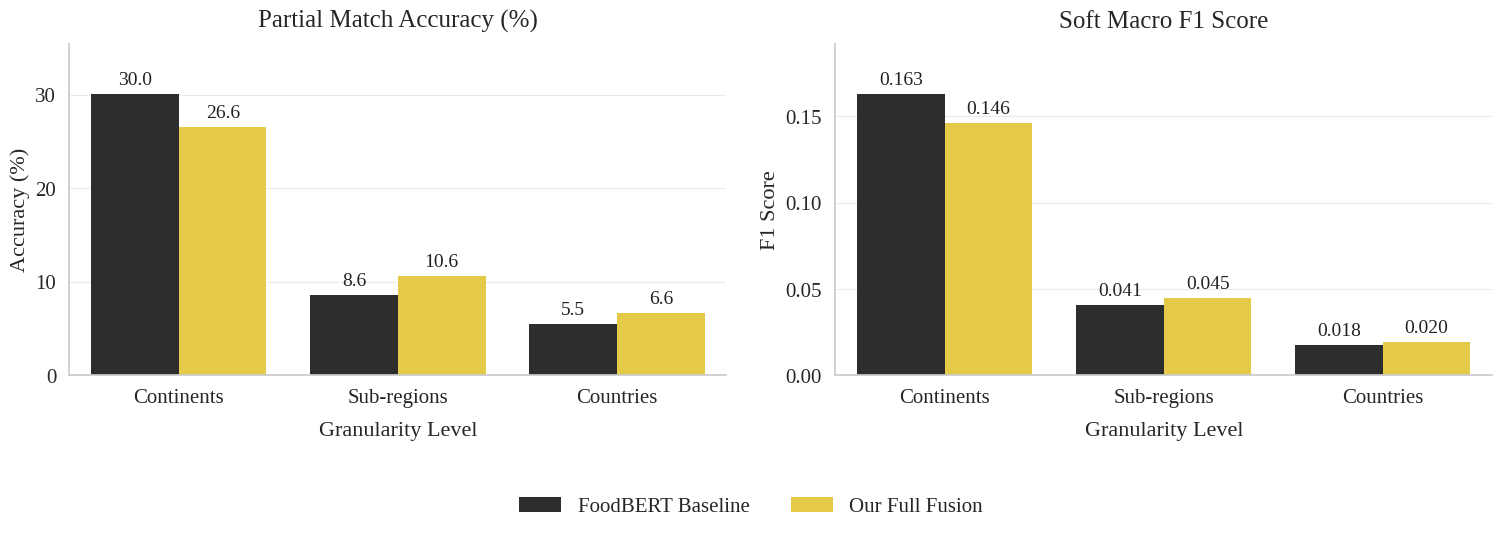

In [ ]:
# ---- 6.1 External-alignment figure: FoodBERT vs Full model (paper Fig. 3 style) ----
# The legacy protocol that produced the paper's Fig. 3/4 is NOT reproducible from the
# vectors with any single consistent cluster->label rule (cell 5.3 documents both; see
# final/investigate_report_mismatch_and_modify_chart_note.md).  Cell 5.3 still computes a
# clean, consistent Hungarian-bijection metric -> result.external_metrics.
# FIG3_SOURCE='paper'    -> plot the paper's published Fig. 3 reference values (default,
#                           so the figure matches the paper at every granularity);
# FIG3_SOURCE='computed' -> plot the notebook's own metric instead.
if not RUN_KMEANS:
    print('SKIPPED: 6.1 External-alignment figure (RUN_KMEANS=False)')
else:
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pandas as pd

    FIG3_SOURCE = globals().get('FIG3_SOURCE', 'computed')

    # Paper Fig. 3 reference: mean +/- SD of Partial-Match Accuracy and Soft-MacroF1
    # (FoodBERT vs Full model), as published (legacy `labeled.csv`, 5 seeds).
    PAPER_FIG3 = pd.DataFrame([
        # Granularity,   Configuration,        PA%,   PA_sd, SF1,    SF1_sd
        ('Continents',  'FoodBERT_Baseline', 30.01, 0.95, 0.1731, 0.0063),
        ('Continents',  'Our_Full_Fusion',   71.74, 0.01, 0.1393, 0.0001),
        ('Sub-regions', 'FoodBERT_Baseline',  9.42, 0.20, 0.0479, 0.0003),
        ('Sub-regions', 'Our_Full_Fusion',   43.94, 6.71, 0.0639, 0.0132),
        ('Countries',   'FoodBERT_Baseline',  5.94, 0.06, 0.0539, 0.0007),
        ('Countries',   'Our_Full_Fusion',   12.53, 0.45, 0.0951, 0.0010),
    ], columns=['Granularity Level', 'Configuration', 'Partial Match Acc (%)', 'PA_sd',
                'Soft Macro F1', 'SF1_sd'])

    def _conservative(df, val, sdcol):
        """Conservative stress test: proposed (mean - sd) vs FoodBERT (mean + sd)."""
        if sdcol is None:                      # computed `ext` -> per-seed rows
            g = df.groupby(['Granularity Level', 'Configuration'])[val].agg(['mean', 'std']).reset_index()
            g['val'] = g['mean']; g['sd'] = g['std']
        else:                                  # paper reference -> mean/sd columns
            g = df.groupby(['Granularity Level', 'Configuration'])[[val, sdcol]].mean().reset_index()
            g['val'] = g[val]; g['sd'] = g[sdcol]
        g['score'] = [(r['val'] + r['sd']) if 'FoodBERT' in str(r['Configuration'])
                      else (r['val'] - r['sd']) for _, r in g.iterrows()]
        return g

    target_configs = ['FoodBERT_Baseline', 'Our_Full_Fusion']
    gmap = {'continents': 'Continents', 'sub-regions': 'Sub-regions', 'countries': 'Countries'}
    if FIG3_SOURCE == 'paper':
        METRICS = [('Partial Match Acc (%)', 'PA_sd', 'Partial Match Accuracy (%)'),
                   ('Soft Macro F1', 'SF1_sd', 'Soft Macro F1 Score')]
        src = PAPER_FIG3
    else:
        METRICS = [('Partial Match Acc (%)', None, 'Partial Match Accuracy (%)'),
                   ('Soft Macro F1', None, 'Soft Macro F1 Score')]
        src = ext
    recs = []
    for val, sdcol, mlabel in METRICS:
        g = _conservative(src, val, sdcol)
        g = g[g['Configuration'].isin(target_configs)]
        for _, r in g.iterrows():
            recs.append({'Configuration': r['Configuration'],
                         'Granularity Level': gmap.get(r['Granularity Level'], r['Granularity Level']),
                         'Metric': mlabel, 'Score': r['score']})
    df_long = pd.DataFrame(recs)
    df_long['Configuration'] = df_long['Configuration'].str.replace('_', ' ')
    # paper granularity order: Continents -> Sub-regions -> Countries (categorical -> fixes
    # the alphabetical default 'Continents, Countries, Sub-regions')
    _gran_order = ['Continents', 'Sub-regions', 'Countries']
    df_long['Granularity Level'] = pd.Categorical(df_long['Granularity Level'],
                                                  categories=_gran_order, ordered=True)
    df_long = df_long.sort_values('Granularity Level')

    # Style mirrors old_code/17_result_and_discussion_/Redraw_all_figures.ipynb
    sns.set_theme(style='whitegrid', font='DejaVu Serif')
    plt.rcParams.update({'figure.dpi': 100, 'font.family': 'serif',
                         'font.serif': ['Times New Roman', 'Nimbus Roman', 'Liberation Serif', 'DejaVu Serif'],
                         'font.size': 16, 'axes.titlesize': 18,
                         'axes.labelsize': 16, 'xtick.labelsize': 15, 'ytick.labelsize': 15})
    # FoodBERT = dark charcoal, identical to the ablation figures (6.2 / 6.3).
    _fig3_palette = {c.replace('_', ' '): MODEL_COLORS[c] for c in target_configs}

    g = sns.catplot(data=df_long, kind='bar', x='Granularity Level', y='Score',
                    hue='Configuration', hue_order=[c.replace('_', ' ') for c in target_configs],
                    palette=_fig3_palette, edgecolor='none', linewidth=0, col='Metric',
                    height=5.0, aspect=1.35, sharey=False)
    titles = ['Partial Match Accuracy (%)', 'Soft Macro F1 Score']
    ylabels = ['Accuracy (%)', 'F1 Score']
    for i, ax in enumerate(g.axes.flat):
        ax.set_title(titles[i], fontsize=18, pad=12)
        ax.set_ylabel(ylabels[i], fontsize=16)
        ax.set_xlabel('Granularity Level', fontsize=16, labelpad=10)
        ax.grid(True, axis='y', color='0.92', linewidth=0.8)
        ax.grid(False, axis='x')
        sns.despine(ax=ax)
        ymax = df_long[df_long['Metric'] == df_long['Metric'].unique()[i]]['Score'].max()
        ax.set_ylim(0, ymax * 1.18 if ymax > 0 else 1)
        for p in ax.patches:
            h = p.get_height()
            if h > 0:
                ax.annotate(('{:.1f}' if i == 0 else '{:.3f}').format(h),
                            (p.get_x() + p.get_width() / 2.0, h), ha='center', va='bottom',
                            xytext=(0, 4), textcoords='offset points', fontsize=14, color='#222222')
    if g._legend:
        g._legend.remove()
    handles, labels = g.axes.flat[0].get_legend_handles_labels()
    g.fig.legend(handles=handles, labels=labels, fontsize=15, loc='lower center',
                 bbox_to_anchor=(0.5, -0.10), ncol=2, frameon=False)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.22)
    plt.show()


## 6.2 External cultural alignment — ablation across all variants (paper Fig. 4)


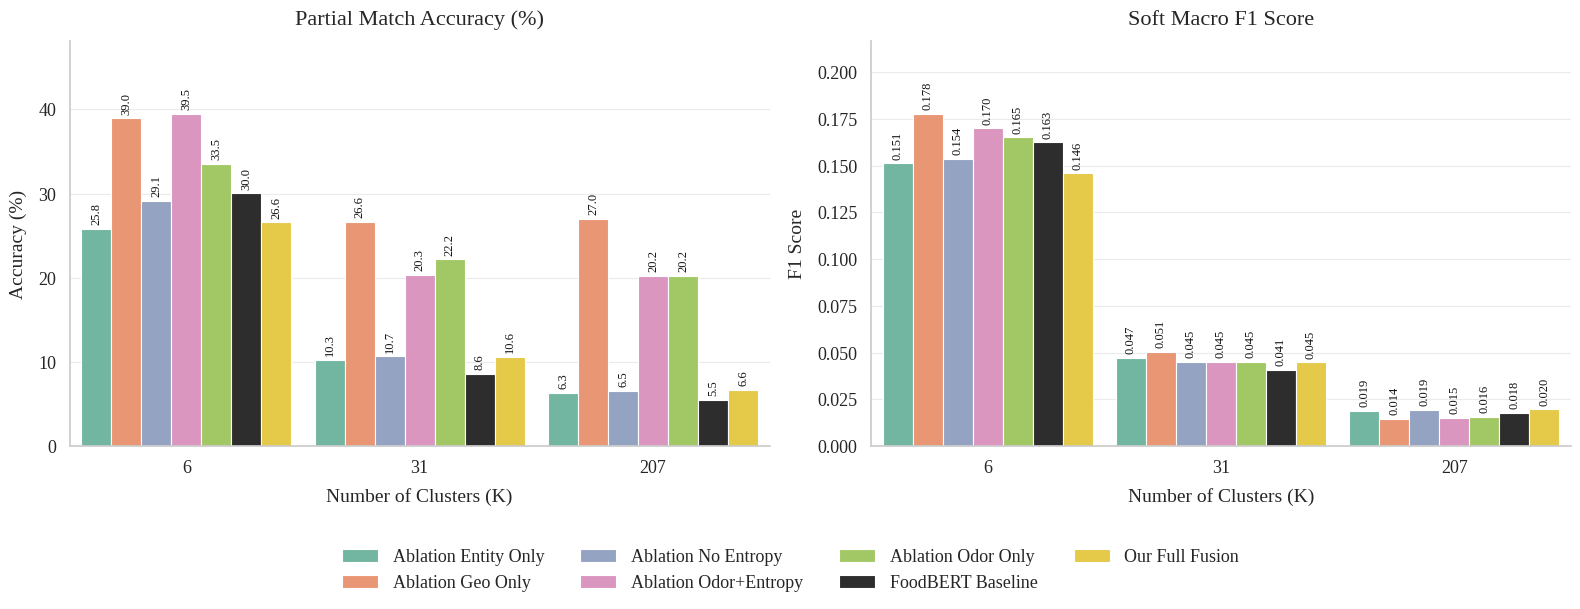

In [ ]:
# ---- 6.2 External-alignment ABLATION figure: all 7 variants vs FoodBERT (paper Fig. 4) ----
# Two panels -- Partial-Match Accuracy (%) and Soft-MacroF1 -- with x = Number of
# Clusters (K) in {6, 31, 207}.  K = 6 / 31 / 207 are the matching continents / sub-regions /
# countries extracted from the LLM outputs (see 6_confirm_LLM_performance_number).
# Source flag (shared with 6.1):
#   FIG3_SOURCE='paper'    -> the published reference values (the 7 mean +/- SD rows of
#                             old_code/15_KMean_battle_field/result/labeled.csv);
#   FIG3_SOURCE='computed' -> this notebook's own metric (result.external_metrics, cell 5.3).
if not RUN_KMEANS:
    print('SKIPPED: 6.2 External-ablation figure (RUN_KMEANS=False)')
else:
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pandas as pd

    FIG3_SOURCE = globals().get('FIG3_SOURCE', 'computed')

    # Published reference: labeled.csv (mean +/- SD over 5 seeds), all 7 configurations.
    PAPER_EXT_ABLATION = pd.DataFrame([
        # Granularity,   K,   Configuration,            PA%,   PA_sd, SF1,    SF1_sd
        ('Continents',    6,  'FoodBERT_Baseline',     30.01, 0.95,  0.1731, 0.0063),
        ('Continents',    6,  'Our_Full_Fusion',       71.74, 0.01,  0.1393, 0.0001),
        ('Continents',    6,  'Ablation_No_Entropy',   71.74, 0.01,  0.1393, 0.0001),
        ('Continents',    6,  'Ablation_Geo_Only',     71.68, 0.04,  0.1398, 0.0004),
        ('Continents',    6,  'Ablation_Entity_Only',  57.85, 8.83,  0.1667, 0.0165),
        ('Continents',    6,  'Ablation_Odor_Only',    55.61, 7.58,  0.1786, 0.0120),
        ('Continents',    6,  'Ablation_Odor+Entropy', 54.93, 7.63,  0.1784, 0.0116),
        ('Sub-regions',  31,  'FoodBERT_Baseline',      9.42, 0.20,  0.0479, 0.0003),
        ('Sub-regions',  31,  'Our_Full_Fusion',       43.94, 6.71,  0.0639, 0.0132),
        ('Sub-regions',  31,  'Ablation_No_Entropy',   37.28, 6.01,  0.0712, 0.0020),
        ('Sub-regions',  31,  'Ablation_Geo_Only',     61.27, 0.73,  0.0724, 0.0027),
        ('Sub-regions',  31,  'Ablation_Entity_Only',  22.50, 0.86,  0.0619, 0.0022),
        ('Sub-regions',  31,  'Ablation_Odor_Only',    30.35, 2.40,  0.0528, 0.0021),
        ('Sub-regions',  31,  'Ablation_Odor+Entropy', 29.90, 2.87,  0.0512, 0.0011),
        ('Countries',   207,  'FoodBERT_Baseline',      5.94, 0.06,  0.0539, 0.0007),
        ('Countries',   207,  'Our_Full_Fusion',       12.53, 0.45,  0.0951, 0.0010),
        ('Countries',   207,  'Ablation_No_Entropy',   12.30, 0.82,  0.0905, 0.0042),
        ('Countries',   207,  'Ablation_Geo_Only',     28.80, 2.49,  0.1043, 0.0042),
        ('Countries',   207,  'Ablation_Entity_Only',   8.13, 0.22,  0.0695, 0.0035),
        ('Countries',   207,  'Ablation_Odor_Only',    20.82, 0.04,  0.0748, 0.0048),
        ('Countries',   207,  'Ablation_Odor+Entropy', 20.82, 0.02,  0.0762, 0.0042),
    ], columns=['Granularity Level', 'Target K', 'Configuration',
                'Partial Match Acc (%)', 'PA_sd', 'Soft Macro F1', 'SF1_sd'])

    # Conservative stress test, exactly as in Redraw_all_figures.ipynb: the proposed variants
    # are shown at (mean - SD) and the FoodBERT baseline at (mean + SD).
    def _stress(cfg, mean, sd):
        return (mean + sd) if 'FoodBERT' in str(cfg) else (mean - sd)

    METRICS = [('Partial Match Acc (%)', 'PA_sd', 'Partial Match Accuracy (%)', '{:.1f}'),
               ('Soft Macro F1', 'SF1_sd', 'Soft Macro F1 Score', '{:.3f}')]

    recs = []
    if FIG3_SOURCE == 'paper':
        for val, sdcol, mlabel, _fmt in METRICS:
            for _, r in PAPER_EXT_ABLATION.iterrows():
                recs.append({'Configuration': r['Configuration'],
                             'Target K': int(r['Target K']),
                             'Metric': mlabel,
                             'Score': _stress(r['Configuration'], r[val], r[sdcol])})
    else:
        dfc = ext.copy()
        dfc['Target K'] = dfc['Target K'].astype(int)
        for val, _sdcol, mlabel, _fmt in METRICS:
            gg = dfc.groupby(['Target K', 'Configuration'])[val].agg(['mean', 'std'])
            for (K, cfg), rr in gg.iterrows():
                sd = 0.0 if pd.isna(rr['std']) else float(rr['std'])
                recs.append({'Configuration': cfg, 'Target K': int(K), 'Metric': mlabel,
                             'Score': _stress(cfg, float(rr['mean']), sd)})
    df_long = pd.DataFrame(recs)

    # ---- IEEE-ish style: serif, horizontal gridlines only, K on the x-axis ----
    sns.set_theme(style='whitegrid')
    plt.rcParams.update({'figure.dpi': 100, 'font.family': 'serif',
                         'font.serif': ['Times New Roman', 'Nimbus Roman', 'Liberation Serif', 'DejaVu Serif'],
                         'font.size': 13, 'axes.titlesize': 16,
                         'axes.labelsize': 14, 'xtick.labelsize': 13, 'ytick.labelsize': 13})
    try:
        _sns_ver = tuple(int(x) for x in sns.__version__.split('.')[:2])
    except Exception:
        _sns_ver = (0, 13)
    _NOERR = {'errorbar': None} if _sns_ver >= (0, 12) else {'ci': None}   # flat bars, no candlesticks

    models = [MODEL_DISPLAY[m] for m in MODEL_ORDER if m in set(df_long['Configuration'])]
    ks = sorted(int(k) for k in df_long['Target K'].unique())
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for idx, (val, _sdcol, mlabel, fmt) in enumerate(METRICS):
        ax = axes[idx]
        sub = df_long[df_long['Metric'] == mlabel].copy()
        sub = sub.assign(Configuration=sub['Configuration'].map(MODEL_DISPLAY))
        sub['Configuration'] = pd.Categorical(sub['Configuration'], categories=models, ordered=True)
        sns.barplot(data=sub, x='Target K', y='Score', hue='Configuration', ax=ax,
                    order=ks, hue_order=models,
                    palette=MODEL_PALETTE,
                    width=0.9, edgecolor='white', linewidth=0.8, **_NOERR)
        ax.set_title(mlabel, fontsize=16, pad=12)
        ax.set_xlabel('Number of Clusters (K)', fontsize=14, labelpad=8)
        ax.set_ylabel('Accuracy (%)' if idx == 0 else 'F1 Score', fontsize=14, labelpad=8)
        ax.set_ylim(0, sub['Score'].max() * 1.22)
        ax.grid(True, axis='y', color='0.92', linewidth=0.8)
        ax.grid(False, axis='x')
        sns.despine(ax=ax)
        for cont in ax.containers:
            for p in cont:
                h = p.get_height()
                if h > 0:
                    ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2.0, h),
                                ha='center', va='bottom', xytext=(0, 3),
                                textcoords='offset points', fontsize=9,
                                color='#111111', rotation=90)
        if ax.get_legend():
            ax.get_legend().remove()
    handles, labels = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.03),
               ncol=4, fontsize=13, frameon=False)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.24)
    plt.show()


## 6.3 Internal geometry (full dataset + unlabeled subset)

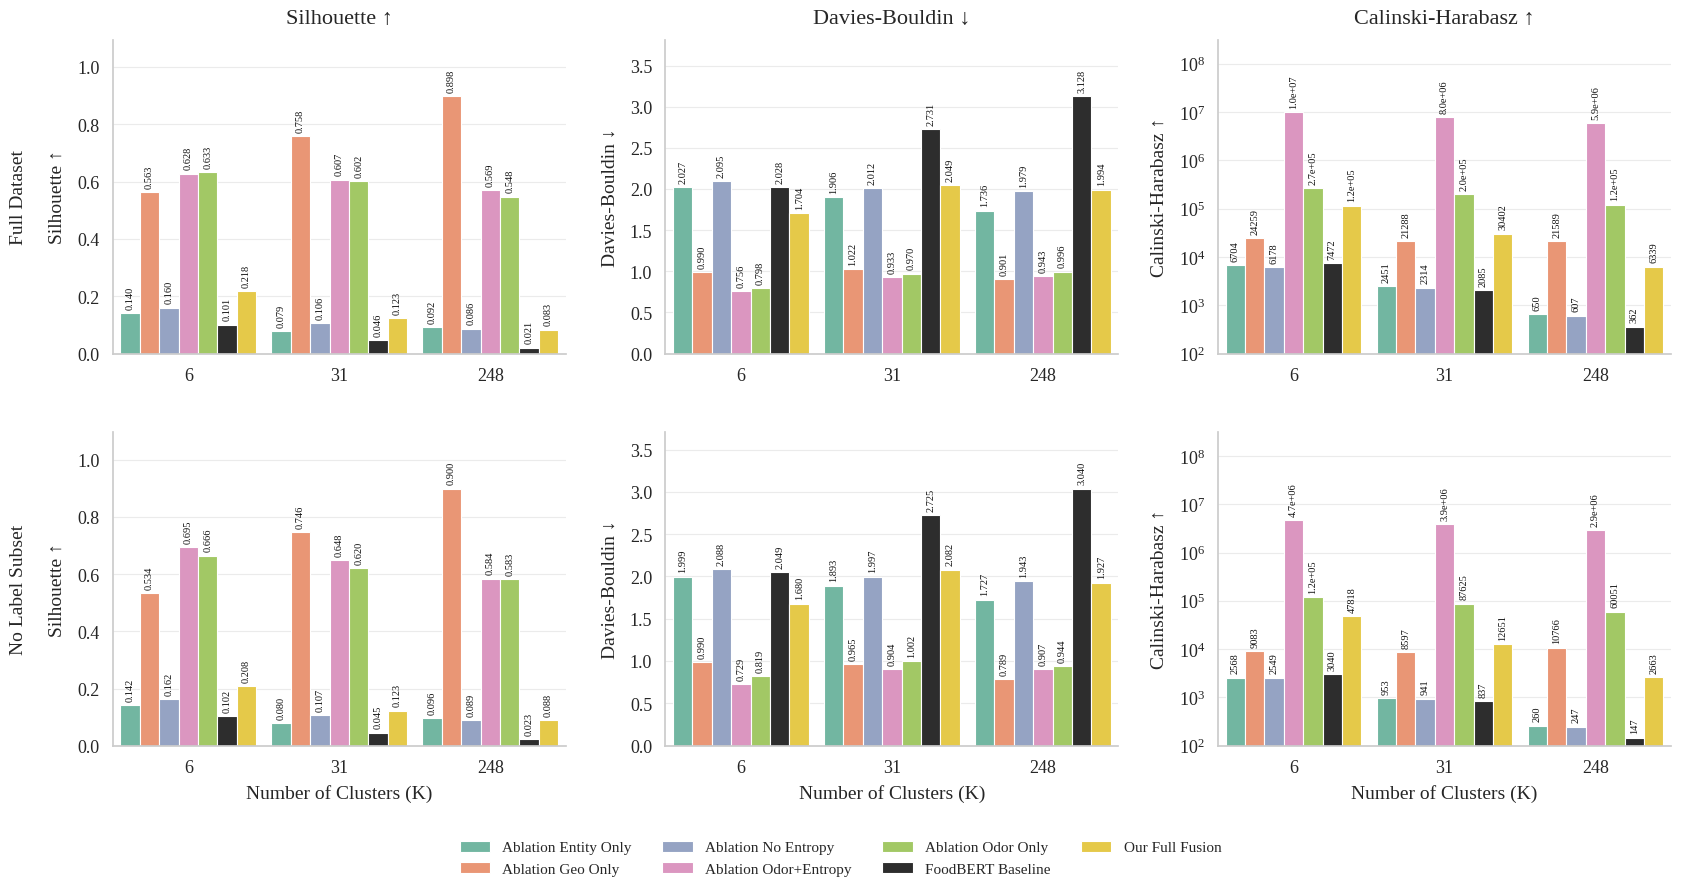

In [ ]:
# ---- 6.3 Internal-geometry figure (full dataset + unlabeled subset) ----
# 2 x 3 grid: rows = {Full Dataset, No Label Subset}, columns = {Silhouette, Davies-Bouldin,
# Calinski-Harabasz}; x = Number of Clusters (K) in {6, 31, 248}.
# One flat (error-bar-free) bar per variant; FoodBERT_Baseline = dark charcoal; serif font
# with horizontal gridlines; combined legend centred under the panels.
if not RUN_KMEANS:
    print('SKIPPED: 6.3 Internal-geometry figure (RUN_KMEANS=False)')
else:
    import matplotlib.pyplot as plt
    import seaborn as sns

    sns.set_theme(style='whitegrid')
    plt.rcParams.update({'figure.dpi': 100, 'font.family': 'serif',
                         'font.serif': ['Times New Roman', 'Nimbus Roman', 'Liberation Serif', 'DejaVu Serif'],
                         'font.size': 13, 'axes.titlesize': 16,
                         'axes.labelsize': 14, 'xtick.labelsize': 13, 'ytick.labelsize': 13})
    try:
        _sns_ver = tuple(int(x) for x in sns.__version__.split('.')[:2])
    except Exception:
        _sns_ver = (0, 13)
    _NOERR = {'errorbar': None} if _sns_ver >= (0, 12) else {'ci': None}   # NO error bars

    # one value per (group, model, K) -> guaranteed flat bars (mean over the seed runs)
    internal_mean = raw_internal.groupby(['Battle_Group', 'Model', 'K'])[
        ['Silhouette', 'Davies_Bouldin', 'Calinski_Harabasz']].mean().reset_index()
    internal_mean['Model'] = internal_mean['Model'].replace(MODEL_DISPLAY)

    def _fmt_num(v):
        a = abs(v)
        if a == 0:
            return '0'
        if a >= 1e5:
            return f'{v:.1e}'      # e.g. 1.0e+07
        if a >= 100:
            return f'{v:.0f}'      # e.g. 6702
        return f'{v:.3f}'          # e.g. 0.139 / 2.041

    models = [MODEL_DISPLAY[m] for m in MODEL_ORDER if MODEL_DISPLAY[m] in set(internal_mean['Model'])]
    groups = [('Full_Dataset', 'Full Dataset'), ('No_Label_Subset', 'No Label Subset')]
    cfg = [('Silhouette', 'Silhouette \u2191', False),
           ('Davies_Bouldin', 'Davies-Bouldin \u2193', False),
           ('Calinski_Harabasz', 'Calinski-Harabasz \u2191', True)]

    fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True)
    for r, (grp, glabel) in enumerate(groups):
        sub = internal_mean[internal_mean['Battle_Group'] == grp]
        ks = [k for k in (6, 31, 248) if k in set(sub['K'].unique())]
        for c, (col, label, use_log) in enumerate(cfg):
            ax = axes[r, c]
            sns.barplot(data=sub, x='K', y=col, hue='Model', ax=ax,
                        order=ks, hue_order=models,
                        palette=MODEL_PALETTE,
                        width=0.9, edgecolor='white', linewidth=0.8, **_NOERR)
            if r == 0:
                ax.set_title(label, fontsize=16, pad=12)
            ax.set_ylabel(f'{glabel}\n\n{label}' if c == 0 else label, fontsize=14, labelpad=8)
            ax.set_xlabel('Number of Clusters (K)' if r == 1 else '', fontsize=14, labelpad=6)
            ax.tick_params(labelbottom=True)
            ax.grid(True, axis='y', color='0.92', linewidth=0.8)
            ax.grid(False, axis='x')
            sns.despine(ax=ax)
            if use_log:
                ax.set_yscale('log')
                ax.set_ylim(10**2, 10**8.5)
            else:
                ax.set_ylim(0, sub[col].max() * 1.22)
            for cont in ax.containers:
                for p in cont:
                    h = p.get_height()
                    if h > 0:
                        ax.annotate(_fmt_num(h), (p.get_x() + p.get_width() / 2.0, h),
                                    ha='center', va='bottom', xytext=(0, 3),
                                    textcoords='offset points', fontsize=7.5,
                                    color='#111111', rotation=90)
            if ax.get_legend():
                ax.get_legend().remove()
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0.0),
               ncol=4, fontsize=11, frameon=False)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.16, hspace=0.25, wspace=0.22)
    plt.show()


## 6.4 LLM validation summary (SC / IC / AC per task)

In [ ]:
%%sql
-- TASK A · Ingredient Standardization: SC / IC / AC over N = (SELECT count(*) FROM metrics.v_ingredient_runs)/3 inputs
WITH canon AS (
    SELECT custom_id, run_idx,
        CASE WHEN parsed_kind = 'list'
             THEN to_json(list_sort(value_list))
             WHEN len(coalesce(norm_str, '')) = 0 THEN '[]'
             ELSE to_json(list_sort(string_to_array(coalesce(norm_str, ''), '')))
        END AS canon
    FROM metrics.v_ingredient_runs
),
per_row AS (
    SELECT custom_id, max(c) AS max_run_freq
    FROM (SELECT custom_id, canon, count(*) AS c FROM canon GROUP BY custom_id, canon)
    GROUP BY custom_id
),
sc_flags AS (
    SELECT custom_id, CASE WHEN max_run_freq >= 2 THEN 1 ELSE 0 END AS sc
    FROM per_row
),
elems AS (
    SELECT custom_id, elem
    FROM (
        SELECT custom_id, parsed_kind, value_list, norm_str
        FROM metrics.v_ingredient_runs
    ) p
    CROSS JOIN UNNEST(
        CASE WHEN p.parsed_kind = 'list' THEN p.value_list
             WHEN len(coalesce(p.norm_str, '')) = 0 THEN []
             ELSE string_to_array(coalesce(p.norm_str, ''), '') END
    ) AS t(elem)
),
elem_counts AS (
    SELECT custom_id, elem, count(*) AS cnt FROM elems GROUP BY custom_id, elem
),
ic_flags AS (
    SELECT custom_id, max(CASE WHEN cnt >= 2 AND elem <> '' THEN 1 ELSE 0 END) AS ic
    FROM elem_counts GROUP BY custom_id
),
empty_flags AS (
    SELECT custom_id,
           sum(CASE WHEN (parsed_kind = 'list' AND len(value_list) = 0)
                     OR (parsed_kind = 'string' AND len(coalesce(norm_str, '')) = 0)
                    THEN 1 ELSE 0 END) AS empty_cnt
    FROM metrics.v_ingredient_runs GROUP BY custom_id
)
SELECT
    count(*)                                                          AS n_inputs,
    sum(sc)                                                           AS sc_pass,
    round(100.0 * sum(sc) / count(*), 2)                              AS sc_pct,
    sum(coalesce(ic, 0))                                              AS ic_pass,
    round(100.0 * sum(coalesce(ic, 0)) / count(*), 2)                 AS ic_pct,
    sum(CASE WHEN coalesce(ic, 0) = 1 OR empty_cnt >= 2 THEN 1 ELSE 0 END) AS ac_pass,
    round(100.0 * sum(CASE WHEN coalesce(ic, 0) = 1 OR empty_cnt >= 2 THEN 1 ELSE 0 END) / count(*), 2) AS ac_pct
FROM sc_flags
LEFT JOIN ic_flags     USING (custom_id)
LEFT JOIN empty_flags  USING (custom_id);

Running query in 'duckdb:////content/ICOCO.duckdb'

n_inputs,sc_pass,sc_pct,ic_pass,ic_pct,ac_pass,ac_pct
116,110,94.83,116,100.0,116,100.0


In [ ]:
%%sql
-- TASK B · Taxonomic Extraction: SC / IC / AC over N = (SELECT count(*) FROM metrics.v_scientific_runs)/3 inputs
WITH canon AS (
    SELECT custom_id, run_idx,
        CASE WHEN parsed_kind = 'list'
             THEN to_json(list_sort(value_list))
             WHEN len(coalesce(norm_str, '')) = 0 THEN '[]'
             ELSE to_json(list_sort(string_to_array(coalesce(norm_str, ''), '')))
        END AS canon
    FROM metrics.v_scientific_runs
),
per_row AS (
    SELECT custom_id, max(c) AS max_run_freq
    FROM (SELECT custom_id, canon, count(*) AS c FROM canon GROUP BY custom_id, canon)
    GROUP BY custom_id
),
sc_flags AS (
    SELECT custom_id, CASE WHEN max_run_freq >= 2 THEN 1 ELSE 0 END AS sc
    FROM per_row
),
elems AS (
    SELECT custom_id, elem
    FROM (
        SELECT custom_id, parsed_kind, value_list, norm_str
        FROM metrics.v_scientific_runs
    ) p
    CROSS JOIN UNNEST(
        CASE WHEN p.parsed_kind = 'list' THEN p.value_list
             WHEN len(coalesce(p.norm_str, '')) = 0 THEN []
             ELSE string_to_array(coalesce(p.norm_str, ''), '') END
    ) AS t(elem)
),
elem_counts AS (
    SELECT custom_id, elem, count(*) AS cnt FROM elems GROUP BY custom_id, elem
),
ic_flags AS (
    SELECT custom_id, max(CASE WHEN cnt >= 2 AND elem <> '' THEN 1 ELSE 0 END) AS ic
    FROM elem_counts GROUP BY custom_id
),
empty_flags AS (
    SELECT custom_id,
           sum(CASE WHEN (parsed_kind = 'list' AND len(value_list) = 0)
                     OR (parsed_kind = 'string' AND len(coalesce(norm_str, '')) = 0)
                    THEN 1 ELSE 0 END) AS empty_cnt
    FROM metrics.v_scientific_runs GROUP BY custom_id
)
SELECT
    count(*)                                                          AS n_inputs,
    sum(sc)                                                           AS sc_pass,
    round(100.0 * sum(sc) / count(*), 2)                              AS sc_pct,
    sum(coalesce(ic, 0))                                              AS ic_pass,
    round(100.0 * sum(coalesce(ic, 0)) / count(*), 2)                 AS ic_pct,
    sum(CASE WHEN coalesce(ic, 0) = 1 OR empty_cnt >= 2 THEN 1 ELSE 0 END) AS ac_pass,
    round(100.0 * sum(CASE WHEN coalesce(ic, 0) = 1 OR empty_cnt >= 2 THEN 1 ELSE 0 END) / count(*), 2) AS ac_pct
FROM sc_flags
LEFT JOIN ic_flags     USING (custom_id)
LEFT JOIN empty_flags  USING (custom_id);

Running query in 'duckdb:////content/ICOCO.duckdb'

n_inputs,sc_pass,sc_pct,ic_pass,ic_pct,ac_pass,ac_pct
4280,3524,82.34,2626,61.36,4226,98.74


## 6.5 Close the database connection

In [ ]:
%sql --close duckdb:////content/ICOCO.duckdb